# Блок матрице

**Садржај:**

1. [Кронекеров производ матрица](#Кронекеров-производ-матрица)
    1. [Особине Кронекеровог производа матрица](#Особине-Кронекеровог-производа-матрица)
    1. [Факторизације Кронекеровог производа](#Факторизације-Кронекеровог-производа)
    1. [Векторизација матрица и Кронекеров производ](#Векторизација-матрица-и-Кронекеров-производ)
1. [Кронекерова сума матрица](#Кронекерова-сума-матрица)
1. [Катри-Рао производ матрица](#Катри-Рао-производ-матрица)

In [1]:
import numpy as np
import numpy.random as rndm
import matplotlib as mplb
import matplotlib.pyplot as plt
from timeit import default_timer as timer

## Кронекеров производ матрица

Кроз блок матрице у могућности смо да нагласимо специјалну структуру унутар матрица, када она постоји. Веома често се у блок партицији понављају неки делови информација. Због тога, уместо да се записује цела блок матрица можемо да користимо Кронекерове операције за скраћени запис блок партиције која подлеже неким правилностима. Не само да Кронекерове операције омогућавају концизну нотацију, већ поседују и низ корисних алгебарских својстава. Прва од Кронекерових операција коју упознајемо је Кронекеров производ матрица.

**Дефиниција 1.** За две матрице $A=[a_{ij}]\in\mathcal{M}_{m\times n}$ и $B=[b_{kl}]\in\mathcal{M}_{p\times q}$ Кронекеров производ матрица $\otimes$ је операција којом се добија матрица $C=A\otimes B\in\mathcal{M}_{mp\times nq},$ а чији је садржај описан следећом блок формом:
$$C=A\otimes B=\begin{bmatrix}a_{00}B&a_{01}B&\dots&a_{0\,n-1}B\\
a_{10}B&a_{11}B&\dots&a_{1\,n-1}B\\
\vdots&\vdots&&\vdots\\
a_{m-1\,0}B&a_{m-1\,1}B&\dots&a_{m-1\,n-1}B\end{bmatrix}.$$

Кронекеров производ као резултат има матрицу чији су блокови скалирана матрица $B$ где су коефицијенти скалирања садржани у матрици $A.$ Не постоји ограничење за димензије матрица у Кронекеровом производу у смислу да могу матрице било којих димензија да учествују у Кронекеровом производу, за разлику од класичног множења матрица или множења матрица члан по члан (Адамаров производ).

У литератури вештачке интелигенције, веома је важно разликовати Кронекеров производ $(\otimes)$ од Адамаровог производа (Hadamard product, $\ast$). Кронекеров производ користимо за структурно дефинисање тежина и експанзију димензија (нпр. код KFAC-а). Адамаров производ представља множење члан-по-члан и користи се у "gate" механизмима код рекурентних мрежа (LSTM, GRU) како би се контролисао проток информација.

Функција `plt.spy()` (скраћено од "Sparsity") један је од најкориснијих алата у инжењерству и нумеричкој линеарној алгебри. Она служи за визуелизацију структуре матрице, односно приказује где се налазе ненула елементи.

Кронекеров производ ствара специфичне, често фракталне и блоковске структуре. Када имате велику матрицу (нпр. 
$100\times100$), немогуће је гледањем у бројеве схватити њену структуру. `plt.spy()` вам омогућава да "се измакнете" и видите ширу слику.

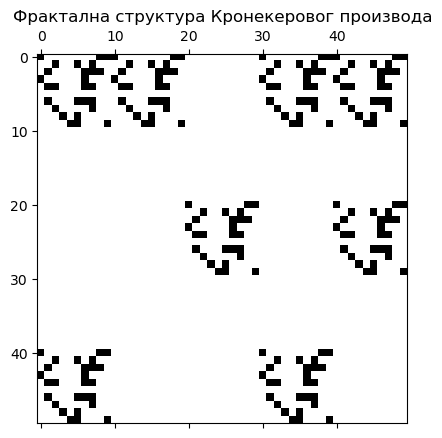

In [2]:
A = rndm.rand(5, 5) > 0.7
B = rndm.rand(10, 10) > 0.7
C = np.kron(A, B)
plt.spy(C)
plt.title("Фрактална структура Кронекеровог производа")
plt.show()

Иако на први поглед делује као теоретски концепт, Кронекеров производ је кључан алат за оптимизацију модерних AI система:

- **Факторизација тежина:** Уместо чувања огромних матрица тежина, модели се могу конвертовати у Кронекерове факторе, чиме се штеди меморија без великог губитка прецизности.

- **Убрзање оптимизације (KFAC):** Алгоритми попут [KFAC](https://arxiv.org/abs/1503.05671)-а користе ово својство за апроксимацију закривљености функције губитка, омогућавајући неуронским мрежама да уче брже и стабилније.

- **Моделирање корелација:** У multi-task learning-у, Кронекеров производ се користи за моделирање корелација између различитих задатака и различитих улазних карактеристика истовремено.

Када упознамо детаљно операције из овог одељка, следећи корак је уопштавање на више димензија кроз тензоре, где Кронекеров производ добија своју пуну интерпретацију.

**Пример 1.** Кронекеров производ две матрице димензија $2\times2$ даје матрицу димензије $4\times4.$

In [3]:
A=np.array([[1,2],[3,4]])
B=np.array([[5,6],[7,8]])
np.kron(A,B)

array([[ 5,  6, 10, 12],
       [ 7,  8, 14, 16],
       [15, 18, 20, 24],
       [21, 24, 28, 32]])

Кронекеров производ матрица димензије $3\times2$ и $3\times3$ даје матрицу димензије $9\times6$

In [4]:
A=np.block([[A],[0,1]])
I=np.eye(3)
I[:-1,:-1]=B
B=I
A,B

(array([[1, 2],
        [3, 4],
        [0, 1]]),
 array([[5., 6., 0.],
        [7., 8., 0.],
        [0., 0., 1.]]))

In [5]:
np.shape(A), np.shape(B)

((3, 2), (3, 3))

In [6]:
np.kron(A,B), np.shape(np.kron(A,B))

(array([[ 5.,  6.,  0., 10., 12.,  0.],
        [ 7.,  8.,  0., 14., 16.,  0.],
        [ 0.,  0.,  1.,  0.,  0.,  2.],
        [15., 18.,  0., 20., 24.,  0.],
        [21., 24.,  0., 28., 32.,  0.],
        [ 0.,  0.,  3.,  0.,  0.,  4.],
        [ 0.,  0.,  0.,  5.,  6.,  0.],
        [ 0.,  0.,  0.,  7.,  8.,  0.],
        [ 0.,  0.,  0.,  0.,  0.,  1.]]),
 (9, 6))

***

**Пример 2.** Потражићемо Кронекеров производ две јединичне матрице $I_2,I_3.$
\begin{align}
I_2\otimes I_3&=\begin{bmatrix}1&0\\0&1\end{bmatrix}\otimes I_3
=\begin{bmatrix}1\cdot I_3&0\cdot I_3\\0\cdot I_3&1\cdot I_3\end{bmatrix}
=\begin{bmatrix}I_3&O_3\\O_3&I_3\end{bmatrix}\\
&=\left[\begin{array}{ccc|ccc}1&0&0&0&0&0\\
0&1&0&0&0&0\\0&0&1&0&0&0\\\hline
0&0&0&1&0&0\\0&0&0&0&1&0\\0&0&0&0&0&1
\end{array}\right]=I_6.
\end{align}

In [7]:
I2=np.eye(2)
I3=np.eye(3)
np.kron(I2,I3)

array([[1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0.],
       [0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 1.]])

In [8]:
np.kron(I3,I2)

array([[1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0.],
       [0., 0., 0., 0., 1., 0.],
       [0., 0., 0., 0., 0., 1.]])

Важи и општије тврђење $I_m\otimes I_n=I_{mn}.$

Креираћемо шаблон шаховске табле користећи Кронекеров производ.

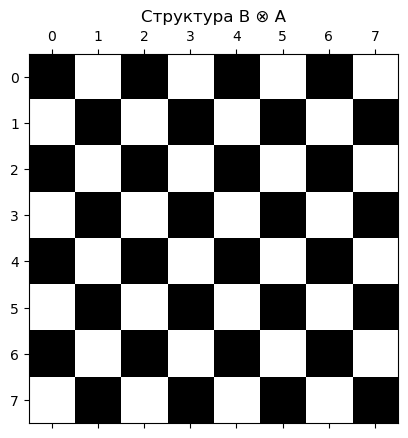

In [9]:
A = np.eye(2)
B = np.ones((4, 4))          
C = np.kron(B, A)

plt.spy(C)
plt.title("Структура B ⊗ A");

***

**Пример 3.** Потражићемо Кронекеров производ матрица $I_2$ и $M=\begin{bmatrix}1&2&3\\-1&1&0\end{bmatrix}$ у оба смера, $I_2\otimes M$ и $M\otimes I_2.$ У оба производа добићемо матрице једнаких димензија $4\times 6.$

In [10]:
M=np.array([[1,2,3],[-1,1,0]])
np.kron(I2,M)

array([[ 1.,  2.,  3.,  0.,  0.,  0.],
       [-1.,  1.,  0., -0.,  0.,  0.],
       [ 0.,  0.,  0.,  1.,  2.,  3.],
       [-0.,  0.,  0., -1.,  1.,  0.]])

In [11]:
np.kron(M,I2)

array([[ 1.,  0.,  2.,  0.,  3.,  0.],
       [ 0.,  1.,  0.,  2.,  0.,  3.],
       [-1., -0.,  1.,  0.,  0.,  0.],
       [-0., -1.,  0.,  1.,  0.,  0.]])

Видимо да је $I_2\otimes M$ блок дијагонална матрица чији су дијагонални блокови једнаки матрици $M.$ Са друге стране $M\otimes I_2$ представља блок матрицу чији су сви блокови скаларне матрице (дијагоналне матрица са једнаким дијагоналним елементима). Закључујемо да операција Кронекеровог производа није комутативна, тј. у општем случају је 
$$A\otimes B\neq B\otimes A.$$

За вежбу пробати резултате Кронекеровог производа две дијагоналне матрице са различитим распоредом чинилаца у производу.

***

**Пример 4.** Кронекеров производ вектора и матрице има једноставну форму. Вектор може бити вектор-колона или вектор-врста.
\begin{align}
&\begin{bmatrix}a_0\\a_1\\\vdots\\a_{m-1}\end{bmatrix}
B
=\begin{bmatrix}
a_0B\\
a_1B\\
\vdots\\
a_{m-1}B
\end{bmatrix}\qquad
&&\begin{bmatrix}a_0&a_1&\dots&a_{m-1}\end{bmatrix}
B
=\begin{bmatrix}
a_0B&a_1B&\dots&a_{m-1}B
\end{bmatrix}
\end{align}

Специјално, спољашњи производ два вектора се поклапа са њиховим Кронекеровим производом.
\begin{align}
\begin{bmatrix}a_0\\a_1\\\vdots\\a_{m-1}\end{bmatrix}
\begin{bmatrix}b_0&b_1&\dots&b_{n-1}\end{bmatrix}
&=\begin{bmatrix}
a_0b_0&a_0b_1&\dots&a_0b_{n-1}\\
a_1b_0&a_1b_1&\dots&a_1b_{n-1}\\
\vdots&\vdots&&\vdots\\
a_{m-1}b_0&a_{m-1}b_1&\dots&a_{m-1}b_{n-1}
\end{bmatrix}
=\begin{bmatrix}
a_0\begin{bmatrix}b_0&b_1&\dots&b_{n-1}\end{bmatrix}\\
a_1\begin{bmatrix}b_0&b_1&\dots&b_{n-1}\end{bmatrix}\\
\vdots\\
a_{m-1}\begin{bmatrix}b_0&b_1&\dots&b_{n-1}\end{bmatrix}
\end{bmatrix}\\
&=\begin{bmatrix}a_0\\a_1\\\vdots\\a_{m-1}\end{bmatrix}\otimes
\begin{bmatrix}b_0&b_1&\dots&b_{n-1}\end{bmatrix}.
\end{align}

In [12]:
a=np.array([1,2,3,0,-1])
b=np.array([-1,-2,0,1])
np.kron(a.reshape(5,1),b)

array([[-1, -2,  0,  1],
       [-2, -4,  0,  2],
       [-3, -6,  0,  3],
       [ 0,  0,  0,  0],
       [ 1,  2,  0, -1]])

In [13]:
np.outer(a,b)

array([[-1, -2,  0,  1],
       [-2, -4,  0,  2],
       [-3, -6,  0,  3],
       [ 0,  0,  0,  0],
       [ 1,  2,  0, -1]])

Интересантно је да у случају спољашњег производа вектора $ab^T$ важи нека врста комутативности Кронекеровог производа ових вектора:
$$a\otimes b^T=b^T\otimes a.$$
\begin{align}
\begin{bmatrix}b_0&b_1&\dots&b_{n-1}\end{bmatrix}\otimes
\begin{bmatrix}a_0\\a_1\\\vdots\\a_{m-1}\end{bmatrix}&=
\begin{bmatrix}b_0\begin{bmatrix}a_0\\a_1\\\vdots\\a_{m-1}\end{bmatrix}&
b_1\begin{bmatrix}a_0\\a_1\\\vdots\\a_{m-1}\end{bmatrix}&\dots&
b_{n-1}\begin{bmatrix}a_0\\a_1\\\vdots\\a_{m-1}\end{bmatrix}\end{bmatrix}\\
&=\begin{bmatrix}
a_0b_0&a_0b_1&\dots&a_0b_{n-1}\\
a_1b_0&a_1b_1&\dots&a_1b_{n-1}\\
\vdots&\vdots&&\vdots\\
a_{m-1}b_0&a_{m-1}b_1&\dots&a_{m-1}b_{n-1}
\end{bmatrix}
=\begin{bmatrix}
a_0\begin{bmatrix}b_0&b_1&\dots&b_{n-1}\end{bmatrix}\\
a_1\begin{bmatrix}b_0&b_1&\dots&b_{n-1}\end{bmatrix}\\
\vdots\\
a_{m-1}\begin{bmatrix}b_0&b_1&\dots&b_{n-1}\end{bmatrix}
\end{bmatrix}\\
&=\begin{bmatrix}a_0\\a_1\\\vdots\\a_{m-1}\end{bmatrix}\otimes
\begin{bmatrix}b_0&b_1&\dots&b_{n-1}\end{bmatrix}
\end{align}
Таква комутативност не важи за сам спољашњи производ.
$$ab^T\neq ba^T=(ab^T)^T$$

In [14]:
np.kron(b,a.reshape(5,1))

array([[-1, -2,  0,  1],
       [-2, -4,  0,  2],
       [-3, -6,  0,  3],
       [ 0,  0,  0,  0],
       [ 1,  2,  0, -1]])

In [15]:
np.outer(b,a)

array([[-1, -2, -3,  0,  1],
       [-2, -4, -6,  0,  2],
       [ 0,  0,  0,  0,  0],
       [ 1,  2,  3,  0, -1]])

***

**Задатак 1.** Нека је $\theta$ нула-вектор и $O$ нула-матрица, тада за произвољну матрицу $A$ важе једнакости:
$$\theta\otimes A=A\otimes\theta=O,\qquad
O\otimes A=A\otimes O=O,$$
где димензије нула-матрица у горњим изразима нису неопходно једнаке. Доказати.

**Решење:**

Било да се нулом множи нека матрица у блоку, или да се било којим бројем множи нула-матрица, резултат је нула-матрица.

Показаћемо доказано и на конкретном примеру.

In [16]:
teta=np.zeros((5,1))
A=rndm.rand(3,2)
O=np.zeros((2,3))
np.kron(teta,A), np.shape(np.kron(teta,A))

(array([[0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.]]),
 (15, 2))

In [17]:
np.kron(A,teta), np.shape(np.kron(A,teta))

(array([[0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.],
        [0., 0.]]),
 (15, 2))

In [18]:
np.kron(O,A)

array([[0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]])

In [19]:
np.kron(A,O)

array([[0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]])

***

**Задатак 2.** Нека је $I$ јединична матрица и  $A$ произвољна матрица. Тада је 
$$I\otimes A=\begin{bmatrix}A&O&\dots&O\\O&A&\dots&O\\ \vdots&\vdots&&\vdots\\
O&O&\dots&A\end{bmatrix},\qquad
A\otimes I=\begin{bmatrix}a_{00}I&a_{01}I&\dots&a_{0n}I\\
a_{10}I&a_{11}I&\dots&a_{1n}I\\
\vdots&\vdots&&\vdots\\
a_{m0}I&a_{m1}I&\dots&a_{mn}I
\end{bmatrix}.
$$
Доказати.

**Решење:**

Директне последице дефиниције Кронекеровог производа.

Приметимо да у случају квадартне матрице $A\in\mathcal{M}_{n\times n}$ истоветном пермутацијом врста и колона можемо довести матрицу $A\otimes I$ на облик $I\otimes A.$ Како је то паран број пермутација, за детерминанте ових матрица важи 
$$\det(I_m\otimes A)=\det(A\otimes I_m)=\det(A)^m.$$

***

Пошто се у машинском учењу скоро никада не процесира само један податак, већ цели batch-ови, Кронекеров производ природно описује ту структуру. Он омогућава компактан запис ситуације у којој се иста линеарна трансформација (матрица $A$) примењује независно на сваки узорак. 
Ако матрица $I_k$ представља идентитет који индексира $k$ узорака у једном batch-у, тада
$$
I_k \otimes A
$$
има блок-дијагоналну структуру са $k$ копија матрице $A$ на дијагонали. Интуитивно, Кронекеров производ $I_k \otimes A$ „размножава“ матрицу $A$ дуж batch-осе, тако да сваки од $k$ узорака добија сопствену копију оператора $A.$ Зато ова матрица тачно описује чињеницу да се иста трансформација примењује на све узорке у batch-у, тј. формлано записује операцију која **паралелно извршава $A$ над свим узорцима**. Ради се о математичком запису структуре batch обраде, а не о имплементацији или посебној рачунској техници.

**Пример 5.**  Показаћемо да Кронекеров производ неких значајних типова матрица са јединичном матрицом чува  њихова посебна својства. За почетак, претпоставимо да је $А$ горње троугаона. 
$$I\otimes A=\begin{bmatrix}A&O&\dots&O\\O&A&\dots&O\\ \vdots&\vdots&&\vdots\\
O&O&\dots&A\end{bmatrix},\qquad
A\otimes I=\begin{bmatrix}a_{00}I&a_{01}I&\dots&a_{0n}I\\
O&a_{11}I&\dots&a_{1n}I\\
\vdots&\vdots&&\vdots\\
O&O&\dots&a_{nn}I
\end{bmatrix}.
$$
У производу $I\otimes A$ сви дијагонални блокови су горње троугаоне матрице, па је и цела матрица $I\otimes A$ горње троугаона. Са друге стране, у производу $A\otimes I$ сви дијагонални блокови су дијагоналне матрице. Због тога је цела матрица $A\otimes I$ горње троугаона.

Претпоставимо сада да је $А$ ортогонална матрица, $AA^T=A^TA=I,$ и означимо $Q=I\otimes A.$ Тада је
$$QQ^T=\begin{bmatrix}A&O&\dots&O\\O&A&\dots&O\\ \vdots&\vdots&&\vdots\\
O&O&\dots&A\end{bmatrix}
\begin{bmatrix}A^T&O&\dots&O\\O&A^T&\dots&O\\ \vdots&\vdots&&\vdots\\
O&O&\dots&A^T\end{bmatrix}
=\begin{bmatrix}AA^T&O&\dots&O\\O&AA^T&\dots&O\\ \vdots&\vdots&&\vdots\\
O&O&\dots&AA^T\end{bmatrix}=I.$$

Уведимо сада ознаку $Q=A\otimes I_m=\begin{bmatrix}a_{00}I_m&a_{01}I_m&\dots&a_{0n}I_m\\
a_{10}I_m&a_{11}I_m&\dots&a_{1n}I_m\\
\vdots&\vdots&&\vdots\\
a_{n0}I_m&a_{n1}I_m&\dots&a_{nn}I_m
\end{bmatrix}.$ Проверавамо да ли је $Q$ ортогонална на основу правила за множење блок матрица:
\begin{align}
QQ^T&=\begin{bmatrix}a_{00}I&a_{01}I&\dots&a_{0n}I\\
a_{10}I&a_{11}I&\dots&a_{1n}I\\
\vdots&\vdots&&\vdots\\
a_{n0}I&a_{n1}I&\dots&a_{nn}I
\end{bmatrix}
\begin{bmatrix}a_{00}I&a_{10}I&\dots&a_{n0}I\\
a_{01}I&a_{11}I&\dots&a_{n1}I\\
\vdots&\vdots&&\vdots\\
a_{0n}I&a_{1n}I&\dots&a_{nn}I
\end{bmatrix}\\
&=\begin{bmatrix}
(a_{00}^2+a_{01}^2+\dots+a_{0n}^2)I&(a_{00}a_{10}+a_{01}a_{11}+\dots+a_{0n}a_{1n})I&\dots
&(a_{00}a_{n0}+a_{01}a_{n1}+\dots+a_{0n}a_{nn})I\\
(a_{10}a_{00}+a_{11}a_{01}+\dots+a_{1n}a_{0n})I&(a_{10}^2+a_{11}^2+\dots+a_{1n}^2)I&\dots
&(a_{10}a_{n0}+a_{11}a_{n1}+\dots+a_{1n}a_{nn})I\\
\vdots&\vdots&&\vdots\\
(a_{n0}a_{00}+a_{n1}a_{01}+\dots+a_{nn}a_{0n})I&(a_{n0}a_{10}+a_{n1}a_{11}+\dots+a_{nn}a_{1n})I&\dots
&(a_{n0}^2+a_{n1}^2+\dots+a_{nn}^2)I
\end{bmatrix}\\
&=(AA^T)\otimes I_m=I_n\otimes I_m=I_{mn}.
\end{align}

***

Веома често је корисно да се особине Кронекеровог производа анализирају кроз мање делове матрица фактора. На тај начине се кроз мање порције резултата може да размишља о његовим особинама.

**Пример 6.** Уколико је матрица $A$ дата у блок форми $A=\begin{bmatrix}A_{00}&A_{01}\\A_{10}&A_{11}\end{bmatrix},$ тада се и израчунавање Кронекеровог производа може да искаже на сличан начин:
$$A\otimes B=\begin{bmatrix}A_{00}&A_{01}\\A_{10}&A_{11}\end{bmatrix}\otimes B=
\begin{bmatrix}A_{00}\otimes B&A_{01}\otimes B\\A_{10}\otimes B&A_{11}\otimes B\end{bmatrix}.$$

И у општијем случају, тј. за блок поделу
$A=\begin{bmatrix}
A_{00} & A_{01} & \dots &A_{0\nu}\\
A_{10} & A_{11} & \dots &A_{1\nu}\\
\vdots & \vdots & \ddots & \vdots\\
A_{\mu0} & A_{\mu1} & \dots &A_{\mu \nu}
\end{bmatrix}$
важи


$$A\otimes B=\begin{bmatrix}
A_{00} & A_{01} & \dots &A_{0\nu}\\
A_{10} & A_{11} & \dots &A_{1\nu}\\
\vdots & \vdots & \ddots & \vdots\\
A_{\mu0} & A_{\mu1} & \dots &A_{\mu \nu}\end{bmatrix}\otimes B=
\begin{bmatrix} A_{00}\otimes B & A_{01}\otimes B & \dots &A_{0\nu}\otimes B\\
A_{10}\otimes B & A_{11}\otimes B & \dots &A_{1\nu}\otimes B\\
\vdots & \vdots & \ddots & \vdots\\
A_{\mu0}\otimes B & A_{\mu1}\otimes B & \dots &A_{\mu \nu}\otimes B\end{bmatrix}.$$

***

**Пример 7.** Један од најједноставнијих примера примене Кронекеровог производа везан је за интерполацију. Приказаћемо је на примеру функције од две променљиве са малим бројем чворова. Претпоставимо да је дата функција $f(x,y)$ својим вредностима у чворовима који образују темена правоугаоника: $(a_0,b_0),\ (a_1,b_0),\ (a_0,b_1),\ (a_1,b_1).$ Уведимо ознаке $f_{ij}=f(a_i,b_j),\ i,j\in(2).$ То су узорци функције.

На основу ових информација о функцији $f(x,y)$ креирамо полином другог степена од две променљиве са одоговарајућим бројем непознатих коефицијената, нпр. $p(x,y)=\alpha_0+\alpha_1x+\alpha_2y+\alpha_3xy.$ Коефицијенете полинома $p(x,y)$ добијамо на основу интерполационих услова
$$p(a_i,b_j)=f_{ij},\ i,j\in(2).$$

Интерполациони услови доводе до система линеарних једначина по непознатим коефицијентима $\alpha_i,$ 
$$\begin{cases}
\alpha_0+\alpha_1a_0+\alpha_2b_0+\alpha_3a_0b_0=f_{00},\\
\alpha_0+\alpha_1a_1+\alpha_2b_0+\alpha_3a_1b_0=f_{10},\\
\alpha_0+\alpha_1a_0+\alpha_2b_1+\alpha_3a_0b_1=f_{01},\\
\alpha_0+\alpha_1a_1+\alpha_2b_1+\alpha_3a_1b_1=f_{11}.
\end{cases}$$
Систем у матричном облику гласи
$$\begin{bmatrix}1&a_0&b_0&a_0b_0\\
1&a_1&b_0&a_1b_0\\1&a_0&b_1&a_0b_1\\
1&a_1&b_1&a_1b_1\end{bmatrix}
\begin{bmatrix}\alpha_0\\ \alpha_1\\ \alpha_2\\ \alpha_3\end{bmatrix}
=\begin{bmatrix}f_{00}\\f_{10}\\f_{01}\\f_{11}\end{bmatrix}.$$

Систем је сагласан када су $a_0\neq a_1$ и $b_0\neq b_1$ (чворови образују прави правоугаоник), и тада поседује јединствено решење по непознатим коефицијентима. Матрица система може да се напише помоћу Кронекеровог производа на следећи начин:
$$\begin{bmatrix}1&a_0&b_0&a_0b_0\\
1&a_1&b_0&a_1b_0\\1&a_0&b_1&a_0b_1\\
1&a_1&b_1&a_1b_1\end{bmatrix}=
\begin{bmatrix}\begin{bmatrix}1&a_0\\1&a_1\end{bmatrix}&b_0\begin{bmatrix}1&a_0\\1&a_1\end{bmatrix}\\
\begin{bmatrix}1&a_0\\1&a_1\end{bmatrix}&b_1\begin{bmatrix}1&a_0\\1&a_1\end{bmatrix}\end{bmatrix}
=\begin{bmatrix}1&b_0\\1&b_1\end{bmatrix}\otimes\begin{bmatrix}1&a_0\\1&a_1\end{bmatrix}=B\otimes A,$$
$$A=\begin{bmatrix}1&a_0\\1&a_1\end{bmatrix},\qquad B=\begin{bmatrix}1&b_0\\1&b_1\end{bmatrix}.$$

Приметимо да не доводи сваки распоред једначина у систему до Кронекеровог облика. Рецимо, заменом места друге и треће једначине губи се могућност компактног представљања преко Кронекеровог производа две матрице.

***

### Особине Кронекеровог производа матрица

Кронекеров производ није само начин компактног представљања великих блок матрица. Ова операција поседује низ корисних алгебарских својстава. Најпре упознајемо везу Кронекеровог производа са стандардним операцијама над матрицама.

**Теорема 1.** Нека су $A\in\mathcal{M}_{n\times n}$ и $B\in\mathcal{M}_{m\times m}$ две квадратне матрице. Тада је
$${\rm tr}(A\otimes B)={\rm tr}(A)\,{\rm tr}(B).$$

**ДОКАЗ:** Како је
$$A\otimes B=\begin{bmatrix}a_{00}B&a_{01}B&\dots&a_{0\,n-1}B\\
a_{10}B&a_{11}B&\dots&a_{1\,n-1}B\\
\vdots&\vdots&&\vdots\\
a_{n-1\,0}B&a_{n-1\,1}B&\dots&a_{n-1\,n-1}B\end{bmatrix}$$
то је
\begin{align}
{\rm tr}(A\otimes B)&=\displaystyle\sum_{i\in(n)}{\rm tr}(a_{ii} B)=\displaystyle\sum_{i\in(n)}a_{ii} {\rm tr}(B)
={\rm tr}(B)\displaystyle\sum_{i\in(n)}a_{ii} \\
&={\rm tr}(A)\,{\rm tr}(B).
\end{align}

***

**Последица 1.** ${\rm tr}(A\otimes B)={\rm tr}(B\otimes A)$

***

**Теорема 2.** Нека су $A,B,C,D$ произвољне матрице и $\alpha,\beta$ скалари. Тада важи:

1. $\alpha\otimes A=A\otimes\alpha=\alpha A,$
1. $(\alpha A)\otimes(\beta B)=\alpha\beta(A\otimes B),$
1. $A\otimes(B\otimes C)=(A\otimes B)\otimes C,$
1. $(A\otimes B)^T=A^T\otimes B^T,$
1. $A\otimes(B+C)=A\otimes B+A\otimes C,$
1. $(A+B)\otimes C=A\otimes C+B\otimes C,$
1. $(A\otimes B)(C\otimes D)=(AC)\otimes(BD),$
1. $\displaystyle\prod_{i\in(n)}(A_i\otimes B_i)=\left(\prod_{i\in(n)}A_i\right)\otimes
\left(\prod_{i\in(n)}B_i\right).$

У свим изразима подразумева се да су матрице димензија које омогућавају извршење наведених операција.

**ДОКАЗ:** Особине $1.$ и $2.$ остављамо као лаку вежбу.

$3.$

\begin{align}
A\otimes(B\otimes C)&\stackrel{\rm Деф.}{=}
\begin{bmatrix}a_{00}(B\otimes C)&a_{01}(B\otimes C)&\dots&a_{0n}(B\otimes C)\\
a_{10}(B\otimes C)&a_{11}(B\otimes C)&\dots&a_{1n}(B\otimes C)\\
\vdots&\vdots&&\vdots\\
a_{m0}(B\otimes C)&a_{m1}(B\otimes C)&\dots&a_{mn}(B\otimes C)\end{bmatrix}
\stackrel{2.}{=}\begin{bmatrix}(a_{00}B)\otimes C&(a_{01}B)\otimes C&\dots&(a_{0n}B)\otimes C\\
(a_{10}B)\otimes C&(a_{11}B)\otimes C&\dots&(a_{1n}B)\otimes C\\
\vdots&\vdots&&\vdots\\
(a_{m0}B)\otimes C&(a_{m1}B)\otimes C&\dots&(a_{mn}B)\otimes C\end{bmatrix}\\
&\stackrel{\rm Деф.}{=}\begin{bmatrix}a_{00}B&a_{01}B&\dots&a_{0n}B\\
a_{10}B&a_{11}B&\dots&a_{1n}B\\
\vdots&\vdots&&\vdots\\
a_{m0}B&a_{m1}B&\dots&a_{mn}B\end{bmatrix}\otimes C
\stackrel{\rm Деф.}{=}(A\otimes B)\otimes C.
\end{align}

$4.$

\begin{align}
(A\otimes B)^T&\stackrel{\rm Деф.}{=}\begin{bmatrix}a_{00}B&a_{01}B&\dots&a_{0n}B\\
a_{10}B&a_{11}B&\dots&a_{1n}B\\
\vdots&\vdots&&\vdots\\
a_{m0}B&a_{m1}B&\dots&a_{mn}B\end{bmatrix}^T
=\begin{bmatrix}a_{00}B^T&a_{10}B^T&\dots&a_{m0}B^T\\
a_{01}B^T&a_{11}B^T&\dots&a_{m1}B^T\\
\vdots&\vdots&&\vdots\\
a_{0n}B^T&a_{1n}B^T&\dots&a_{mn}B^T\end{bmatrix}\\[8pt]
&\stackrel{\rm Деф.}{=}A^T\otimes B^T.
\end{align}

$5.$

\begin{align}
A\otimes(B+C)&=\begin{bmatrix}a_{00}(B+C)&a_{01}(B+C)&\dots&a_{0n}(B+C)\\
a_{10}(B+C)&a_{11}(B+C)&\dots&a_{1n}(B+C)\\
\vdots&\vdots&&\vdots\\
a_{m0}(B+C)&a_{m1}(B+C)&\dots&a_{mn}(B+C)\end{bmatrix}\\[8pt]
&=\begin{bmatrix}a_{00}B&a_{01}B&\dots&a_{0n}B\\
a_{10}B&a_{11}B&\dots&a_{1n}B\\
\vdots&\vdots&&\vdots\\
a_{m0}B&a_{m1}B&\dots&a_{mn}B\end{bmatrix}+
\begin{bmatrix}a_{00}C&a_{01}C&\dots&a_{0n}C\\
a_{10}C&a_{11}C&\dots&a_{1n}C\\
\vdots&\vdots&&\vdots\\
a_{m0}C&a_{m1}C&\dots&a_{mn}C\end{bmatrix}\\[8pt]
&=A\otimes B+A\otimes C
\end{align}

$6.$

\begin{align}
(A+B)\otimes C&=\begin{bmatrix}(a_{00}+b_{00})C&(a_{01}+b_{01})C&\dots&(a_{0n}+b_{0n})C\\
(a_{10}+b_{10})C&(a_{11}+b_{11})C&\dots&(a_{1n}+b_{1n})C\\
\vdots&\vdots&&\vdots\\
(a_{m0}+b_{m0})C&(a_{m1}+b_{m1})C&\dots&(a_{mn}+b_{mn})C\end{bmatrix}\\[8pt]
&=\begin{bmatrix}a_{00}C&a_{01}C&\dots&a_{0n}C\\
a_{10}C&a_{11}C&\dots&a_{1n}C\\
\vdots&\vdots&&\vdots\\
a_{m0}C&a_{m1}C&\dots&a_{mn}C\end{bmatrix}
+
\begin{bmatrix}b_{00}C&b_{01}C&\dots&b_{0n}C\\
b_{10}C&b_{11}C&\dots&b_{1n}C\\
\vdots&\vdots&&\vdots\\
b_{m0}C&b_{m1}C&\dots&b_{mn}C\end{bmatrix}
\\[8pt]
&=A\otimes C+B\otimes C
\end{align}

7. Нека су матрице $A$ и $C$ типа $2\times2,$ са елементима  $A=\begin{bmatrix}a_{00}&a_{01}\\a_{10}&a_{11}\end{bmatrix}$ и 
$C=\begin{bmatrix}c_{00}&c_{01}\\c_{10}&c_{11}\end{bmatrix}.$ Тада је

\begin{align}
(A\otimes B)(C\otimes D)&=\begin{bmatrix}a_{00}B&a_{01} B\\a_{10} B&a_{11} B\end{bmatrix}
\begin{bmatrix}c_{00} D&c_{01} D\\c_{10} D&c_{11} D\end{bmatrix}\\[8pt]
&=\begin{bmatrix} a_{00}c_{00} BD+a_{01}c_{10}BD & a_{00}c_{01} BD+a_{01}c_{11}BD\\
a_{10}c_{00} BD+a_{11}c_{10}BD & a_{10}c_{01} BD+a_{11}c_{11}BD
\end{bmatrix}\\[8pt]
&=\begin{bmatrix} a_{00}c_{00} +a_{01}c_{10} & a_{00}c_{01} +a_{01}c_{11}\\
a_{10}c_{00} +a_{11}c_{10} & a_{10}c_{01} +a_{11}c_{11}
\end{bmatrix}\otimes (BD)\\[8pt]
&=(AC)\otimes(BD)
\end{align}

Претпоставимо да је ова особина тачна за матрице $A$ и $C$ мањих димензија Нека су сада матрице $A$ и $C$ дате конформном блоковском поделом за множење $AC,$ а саме блоковске поделе су $2\times 2$ на матрице за које је тврђење тачно. Другим речима, подматрице које чине блокове својим димензијама испуњавају услове индукцијске хипотезе. Тада је

\begin{align}
(A\otimes B)(C\otimes D)&=\begin{bmatrix}A_{00}\otimes B&A_{01}\otimes  B\\A_{10}\otimes  B&A_{11}\otimes  B\end{bmatrix}
\begin{bmatrix}C_{00}\otimes  D&C_{01}\otimes  D\\C_{10}\otimes  D&C_{11}\otimes  D\end{bmatrix}\\[8pt]
&=\begin{bmatrix} 
(A_{00}\otimes  B)(C_{00}\otimes D)+(A_{01}\otimes  B)(C_{10}\otimes D) & 
(A_{00}\otimes  B)(C_{01}\otimes D)+(A_{01}\otimes  B)(C_{11}\otimes D)\\
(A_{10}\otimes  B)(C_{00}\otimes D)+(A_{11}\otimes  B)(C_{10}\otimes D) & 
(A_{10}\otimes  B)(C_{01}\otimes D)+(A_{11}\otimes  B)(C_{11}\otimes D)
\end{bmatrix}\\[8pt]
&=\begin{bmatrix} 
(A_{00}C_{00}+A_{01}C_{10})\otimes BD & (A_{00}C_{01}+A_{01}C_{11})\otimes BD\\
(A_{10}C_{00}+A_{11}C_{10})\otimes BD & (A_{00}C_{01}+A_{11}C_{11})\otimes BD
\end{bmatrix}\\[8pt]
&=\begin{bmatrix} 
A_{00}C_{00}+A_{01}C_{10} & A_{00}C_{01}+A_{01}C_{11}\\
A_{10}C_{00}+A_{11}C_{10} & A_{00}C_{01}+A_{11}C_{11}
\end{bmatrix}\otimes BD\\[8pt]
&=(AC)\otimes(BD)
\end{align}

На основу принципа математичке индукције закључујемо да ова особина Кронекеровог производа важи за све матрице $A,B,C,D$ чије димензије дозвољавају рачунање производа $AC$ и $BD.$

Особина $8.$ је само вишеструка сукцесивна примена особине $7$ на основу асоцијативности множења матрица и Кронекеровог производа$.\Box$

***

Особина  мешовитог производа
$$(A \otimes B)(C \otimes D) = (AC \otimes BD)$$  
представља срце ефикасности у многим применама машинског учења, посебно када се користе структуриране матрице тежина.

У дубоком учењу, ако имамо два узастопна слоја са тежинама $W_1 = C \otimes D $ и  $W_2 = A \otimes B,$  
њихова комбинована трансформација остаје унутар истог математичког простора. Уместо да множимо две огромне матрице  
$$ W_2 W_1 $$  
ми једноставно множимо њихове компоненте $AC$ и $BD$.

Ово омогућава:
- **Екстремну компресију параметара:** Читавa секвенца трансформација може се израчунати и чувати у факторисаном облику.  
- **Аналитичку једноставност:** Омогућава лако извођење градијената и оптимизацију унутар „Кронекеровог простора“ без потребе за ширењем (експанзијом) матрица у њихову пуну величину.

Новији научни радови примењују Кронекеров производ директно у архитектурама како би се убрзале конволуције и [Attention механизми](https://en.wikipedia.org/wiki/Attention_(machine_learning)):
- [Kronecker Convolutions](https://arxiv.org/abs/1512.09194): Користе се за смањење редундантности у мапама карактеристика.
- [Fast Matrix Multiplication](https://arxiv.org/pdf/2401.10187): Библиотеке као што је FastKron користе ове идентитете да би извршавале множење матрица на GPU  и до 40 пута брже од стандардних имплементација.

In [20]:
# Димензије фактора (нпр. две матрице 100x100 дају једну 10,000x10,000)
n, m = 100, 100
A, B = rndm.randn(n, n), rndm.randn(m, m)
C, D = rndm.randn(n, n), rndm.randn(m, m)

# 1. СТАНДАРДНИ ПРИСТУП (Множење огромних матрица)
W1 = np.kron(A, B) # Ово прави матрицу 10,000 x 10,000
W2 = np.kron(C, D)

start_naive = timer()
res1 = W2@W1 # Множење 10k x 10k матрица
vreme_naive = timer() - start_naive

# 2. ЕФИКАСНИ ПРИСТУП (Коришћење особине (AC ⊗ BD))
start_eff = timer()
AC = C@A
BD = D@B
res2 = np.kron(AC, BD) # Кронекеров производ малих резултата
vreme_eff = timer() - start_eff

# ПРОВЕРА
print(f"Резултати су идентични: {np.allclose(res1, res2, atol=1e-4)}")
print(f"Време (стандардно): {vreme_naive:.4f}s")
print(f"Време (особина):    {vreme_eff:.4f}s")
print(f"Убрзање: {vreme_naive/vreme_eff:.1f}x")

Резултати су идентични: True
Време (стандардно): 27.0813s
Време (особина):    0.5096s
Убрзање: 53.1x


У наставку упознајемо веома важне последице особине мешовитог производа.

***

**Пример 8.** Последица седме особине Кронекеровог производа, теореме 2., је да у случају регуларних квадратних матрица $A\in\mathcal{M}_{n\times n}$ и $B\in\mathcal{M}_{m\times m}$ имамо
$$(A\otimes B)(A^{-1}\otimes B^{-1})=(A\,A^{-1})\otimes(B\,B^{-1})=I_n\otimes I_m=I_{nm}.$$

Другим речима, ако је велика матрица $A\otimes B$ добијена Кронекеровим производом регуларних матрица $A$ и $B,$ тада је и велика матрица регуларна. Шта више, инверзна матрица велике матрице се такође изражава преко Кронекеровог производа мањих инверзних матрица.

$$ (A\otimes B)^{-1}=A^{-1}\otimes B^{-1} $$

Ово је изузетно важно у:
- решавању великих линеарних система,
- KFAC оптимизацији (где се [Фишерова матрица](https://en.wikipedia.org/wiki/Fisher_information) факторише као $A \otimes G$).

Уместо инверзије огромне матрице, довољно је инвертовати две мале.

У оптимизацији неуронских мрежа, Фишерова информациона матрица $F$ описује закривљеност функције губитка и игра улогу у методама другог реда. Међутим, $F$ је огромна (често величине милиона $\times$ милиона) и директна инверзија је практично немогућа.

[KFAC](https://arxiv.org/abs/2311.00636) користи структуру неуронских слојева да апроксимира Фишерову матрицу као Кронекеров производ две мале матрице:
$$F \approx A \otimes G,$$
где:
- $A$ описује статистику активација,
- $G$ описује статистику градијената.

Захваљујући својству:
$$(A \otimes G)^{-1} = A^{-1} \otimes G^{-1},$$
инверзија огромне матрице своди се на инверзију две мале матрице.  
То омогућава да се **оптимизација другог реда изводи у реалном времену**, што је иначе недостижно за велике моделе.

Овај приступ је један од разлога зашто су Кронекерови фактори постали стандард у ефикасној оптимизацији дубоких мрежа.

Својство инверза се преноси и на уопштене инверзе, специјално и на Мур-Пенроузов инверз,
$$(A\otimes B)^+=A^{+}\otimes B^{+}.$$
Напоменимо да је Мур-Пенроузов инверз својство матрица произвољних димензија.

Показаћемо ово својство помоћу аксиома Мур-Пенроузовог инверза:
\begin{align}
&XX^+X=X,\qquad   &&X^+XX^+=X^+,\\
&(XX^+)^T=XX^+ ,  &&(X^+X)^T=X^+X.
\end{align}

\begin{align}
(A\otimes B)(A^{+}\otimes B^{+})(A\otimes B)&=\big((AA^+)\otimes(BB^+)\big)(A\otimes B)
=(AA^+A)\otimes(BB^+B)=A\otimes B,\\
(A^{+}\otimes B^{+})(A\otimes B)(A^{+}\otimes B^{+})&=\big((A^+A)\otimes(B^+B)\big)(A^{+}\otimes B^{+})
=(A^+AA^+)\otimes(B^+BB^+)=A^+\otimes B^+,\\
\big((A\otimes B)(A^{+}\otimes B^{+})\big)^T&=\big((AA^+)\otimes(BB^+)\big)^T=(AA^+)^T\otimes(BB^+)^T
=(AA^+)\otimes(BB^+)\\&=(A\otimes B)(A^{+}\otimes B^{+}),\\
\big((A^{+}\otimes B^{+})(A\otimes B)\big)^T&=\big((A^+A)\otimes(B^+B)\big)^T=(A^+A)^T\otimes(B^+B)^T
=(A^+A)\otimes(B^+B)\\&=(A^{+}\otimes B^{+})(A\otimes B).
\end{align}

Ово својство је критично у свим сценаријима где су матрице сингуларне (немају инверз) или правоугаоне, што је често случај у модерној анализи података. Показана особина омогућава:
- решавање недовољно одређених или преодређених система огромних димензија (проблем најмањих квадрата),
- ефикасну регуларизацију у тензорским моделима (Ridge Regression и Regularization),
- реконструкција сигнала (Compressed Sensing),
- примене у CP/Tucker декомпозицијама и факторизацијама.

Још једна последица особине мешовитог производа дата је једнакошћу
$$A\in\mathcal{M}_{m\times n},\ B\in\mathcal{M}_{p\times q}\quad\Longrightarrow\quad
A\otimes B=(A\otimes I_p)(I_n\otimes B).$$

Због тога за квадартне матрице $A\in\mathcal{M}_{m\times m},\ B\in\mathcal{M}_{n\times n}$ имамо $A\otimes B=(A\otimes I_n)(I_m\otimes B),$ па је према Коши-Бинеовој формули и коментару из задатка 2:
$$\det(A\otimes B)=\det\big((A\otimes I_n)(I_m\otimes B)\big)=\det(A\otimes I_n)\det(I_m\otimes B)=\det(A)^n\det(B)^m.$$

Наведени пример сугерише да Кронекеров производ може да пренесе још неке особине матрица чинилаца. Проблеми као што су решавање система линеарних једначина, израчунавање детерминанти, сопствених вредности, итд. може да се преведе на одговарајуће потпроблеме матрица чинилаца које су мањих димезија.

***

**Задатак 3.** Кронекеорви производи парова сличних матрица су сличне матрице. Доказати.

**Решење:**

Нека су $A,C\in\mathcal{M}_{n\times n}$ и $B,D\in\mathcal{M}_{m\times m}$ парови сличних матрица, тј. постоје регуларне матрице $T\in\mathcal{M}_{n\times n}$ и $M\in\mathcal{M}_{m\times m}$ тако да важе једнакости
$$A=TCT^{-1},\qquad B=MDM^{-1}. $$

\begin{align}
A\otimes B&=(TCT^{-1})\otimes(MDM^{-1})=(T\otimes M)(C\otimes D)(T^{-1}\otimes M^{-1})\\
&=(T\otimes M)(C\otimes D)(T\otimes M)^{-1},
\end{align}
па су заиста и матрице $A\otimes B$ и $C\otimes D$ сличне.

***

**Последица 2.** Нека су $A\in\mathcal{M}_{n\times n}$ и $B\in\mathcal{M}_{m\times m}$ произвољне кваратне матрице које дозвољавају дијагонализацију, $A=T_AD_AT_A^{-1},$ $B=T_BD_BT_B^{-1}.$ Тада је
$$A\otimes B=(T_A\otimes T_B)(D_A\otimes D_B)(T_A^{-1}\otimes T_B^{-1})$$
дијагонализација матрице $A\otimes B.$ 

***

Дакле, ако су $\lambda_i$ сопствене вредности матрице $A$, а $\mu_j$ сопствене вредности матрице $B$, онда су сопствене вредности Кронекеровог производа:
$$
A \otimes B
$$
једноставно сви производи, рачунајући и вишеструкости сопствених вредности:
$$
\lambda_i \mu_j.
$$
Ово значи да:
- спектар великог оператора добијамо из два мала,
- анализа стабилности и динамике постаје много једноставнија,
- [тензорског производа графова](https://en.wikipedia.org/wiki/Tensor_product_of_graphs) имају спектар који се добија комбиновањем спектра појединачних графова.

Ако су $u_i$ сопствени вектори матрице $A$, а $v_j$ сопствени вектори матрице $B$, онда су вектори:
$$
u_i \otimes v_j
$$
сопствени вектори матрице $A \otimes B$.
Ово је кључно код:
- спектралних метода на производима графова,
- решавања ПДЈ-на на решеткама (дискретизација = Кронекеров производ),
- тензорских метода у машинском учењу.

У рекурентним неуронским мрежама (**RNN**), стабилност учења зависи од спектралног радијуса матрице тежина. Ако тежине имају Кронекерову структуру, можемо контролисати стабилност целе мреже само кроз анализу сопствених вредности малих матрица фактора. 

Зашто је ово важно у ML-у?
- Велики оператори (нпр. Fisher, Hessian, Laplacian) често имају **Кронекерову структуру**.
- Спектрална анализа постаје тривијална: сопствене вредности се добијају као производи.
- Инверзија и псеудоинверзија постају рачунски изводљиве.
- Модели који комбинују више модалитета (простор $\times$ време $\times$ фреквенција) природно воде ка Кронекеровим производима.

Кронекеров производ је, у суштини, алат који омогућава да се огромни проблеми реше као низ малих.

***

### Факторизације Кронекеровог производа

Баш као што је успостављена веза између спектралне декомпозиције квадратних матрица са спектралном декомпозицијом њиховог Кронекеровог производа, могу се успоставити везе са другим факторизацијама. Како бисмо то показали бавимо се неким специјалним факторима у Кронекеровом производу.

**Задатак 4.** Кронекеорв производ две квадратне троугаоне матрице истог типа је поново квадратна троугаона матрица истог типа. Доказати.

**Решење :**

Претпоставимо да су матрице горње троугаоне. Доказ се изводи аналогно у случају доње троугаоних матрица.
\begin{align}
A&=\begin{bmatrix}
a_{00}&a_{01}&\dots&a_{0n}\\
0&a_{11}&\dots&a_{1n}\\
\vdots&\vdots&&\vdots\\
0&0&\dots&a_{nn}\\
\end{bmatrix},\qquad
B=\begin{bmatrix}
b_{00}&b_{01}&\dots&b_{0m}\\
0&b_{11}&\dots&b_{1m}\\
\vdots&\vdots&&\vdots\\
0&0&\dots&b_{mm}\\
\end{bmatrix},\\
&A\otimes B=(A\otimes I_{m+1})(I_{n+1}\otimes B)
\end{align}

Као што је показано у примеру 5, Кронекерови производи $A\otimes I_{m+1}$ и $I_{n+1}\otimes B$ су поново горње троугаоне, па је њихов производ још једном горње троугаона матрица.

***

Наредна тврђења су последица особине 7, теореме 2, и закључака претходног задатака.

**Последица 3.** Ако су $A=L_AR_A,$ $B=L_BR_B$  троугаоне факторизације матрица $A$ и $B,$ тада је $A\otimes B=(L_A\otimes L_B)(R_A\otimes R_B)$ троугаона факторизација њиховог Кронекеровог производа.

***

**Последица 4.** Ако су $A=L_AL_A^T,$ $B=L_BL_B^T$ Чолески факторизације симетричних матрица $A$ и $B,$ тада је $A\otimes B=(L_A\otimes L_B)(L_A\otimes L_B)^T$ факторизација Чолеског њиховог Кронекеровог производа.

***

**Задатак 5.** Кронекеорв производ две ортогоналне матрице је поново ортогонална матрица. Доказати.

**Решење :**

Нека су $Q\in\mathcal{M}_{n\times n}$ и $U\in\mathcal{M}_{m\times m}$ две ортогоналне матрице. Покажимо да је и $Q\otimes U$ поново ортогонална матрица. Како је 
$$(Q\otimes U)(Q\otimes U)^T=(Q\otimes U)(Q^T\otimes U^T)=(QQ^T)\otimes(UU^T)4=I_n\otimes I_m=I_{nm},$$ 
 то је и њихов производ $Q\otimes U$ ортогонална матрица.

***

**Задатак 6.** Кронекеорв производ две матрице пермутација је поново пермутациона матрица. Доказати.

**Решење :**

Нека су $P\in\mathcal{M}_{n\times n}$ и $Q\in\mathcal{M}_{m\times m}$ две матрице пермутација, тј. бинарне ортогоналне матрице. Тада је $P\otimes Q=(P\otimes I_m)(I_n\otimes Q)$ поново бинарна ортогонална матрица, па представља матрицу пермутација.

***

**Последица 5.** Ако су $P_AA=L_AR_A,$ $P_BB=L_BR_B$  троугаоне факторизације са делимичним избором пивот елемента матрица $A$ и $B,$ тада је $(P_A\otimes P_B)(A\otimes B)=(L_A\otimes L_B)(R_A\otimes R_B)$ троугаона факторизација са делимичним избором пивот елемента њиховог Кронекеровог производа.

***

**Последица 6.** Ако су $A=Q_AR_A,$ $B=Q_BR_B,$ дате $QR$ факторизације  матрица $A$ и $B,$ тада $A\otimes B=(Q_A\otimes Q_B)(R_A\otimes R_B)$ представља $QR$ факторизацију њиховог Кронекеровог производа.

***

**Последица 7.** Ако су $A=Q_AD_AQ_A^T,$ $B=Q_BD_BQ_B^T$  спектралне декомпозиције симетричних матрица $A$ и $B,$ тада је $A\otimes B=(Q_A\otimes Q_B)(D_A\otimes D_B)(Q_A\otimes Q_B)^T$ спектрална декомпозиција њиховог Кронекеровог производа.

***

**Последица 8.** Ако су $A=Q_AR_AQ_A^T$ и $B=Q_BR_BQ_B^T$ Шурове декомпозиције квадратних матрица $A$ и $B,$ тада је $A\otimes B=(Q_A\otimes Q_B)(R_A\otimes R_B)(Q_A\otimes Q_B)^T$ Шурова декомпозиција њиховог Кронекеровог производа.

***

**Задатак 7.** SVD декомпозиција Кронекеровог производа две матрице једнак је (до на пермутацију врста и колона) производу Кронекеових производа фактора SVD декомпозиција матрица чинилаца. Доказати.

**Решење:**

Нека су $A$ и $B$ произвољне матрице рангова $r_A$ и $r_B,$ редом. Искористићемо редуковане SVD декомпозиције матрица $A$ и $B$
$$A=U_A\Sigma_A V_A^T,\quad \Sigma_A\in\mathcal{M}_{r_{A}\times r_A},\qquad B=U_B\Sigma_BV_B^T
,\quad \Sigma_B\in\mathcal{M}_{r_{B}\times r_B},$$
при чему су $\Sigma_A$ и $\Sigma_B$ регуларне дијагоналне матрице.

\begin{align}
A\otimes B&=(U_A\Sigma_A V_A^T)\otimes(U_B\Sigma_BV_B^T)
=(U_A\otimes U_B)(\Sigma_A\otimes\Sigma_B)(V_A^T\otimes V_B^T)\\
&=(U_A\otimes U_B)(\Sigma_A\otimes\Sigma_B)(V_A\otimes V_B)^T
\end{align}
Видимо да се редукована SVD декомпозиција матрице $A\otimes B$ добија Кронекеровим производом одговарајућих делова SVD декомпозиција матрица чинилаца, уколико дијагонални елементи матрице $\Sigma_A\otimes\Sigma_B$ остају у опадајућем редоследу. Ако не, вршимо пермутације редова и колона да би се сингуларне вредности поређале у опадајући редослед.  На основу $\Sigma_A\otimes\Sigma_B$ лако добијамо и однос сингуларних вредности матрица $A\otimes B$ и $A,B.$ 

***

**Последица 9.** Ранг Кронекеровог производа матрица једнак је производу рангова матрица чинилаца,
$${\rm rang}(A\otimes B)={\rm rang}(A)\,{\rm rang}(B).$$

***

Ако су $A$ и $B$ ортогоналне матрице, онда је и $A \otimes B$ ортогонална.  Ово се користи у архитектурама као што су **Unitary RNNs**, где се Кронекеров производ примењује за конструкцију великих ортогоналних матрица које, по дефиницији, имају спектрални радијус тачно $1.$ Када током оптимизације желимо да [смањимо спектрални радијус](https://arxiv.org/abs/1705.10142), много је лакше извршити SVD декомпозицију над малим матрицама фактора него над пуном RNN матрицом.

Као што је показано, Кронекеров производ има изузетно богату структуру која омогућава да се многе особине матрица пренесу на производ. Ово је кључно у анализи великих система, тензорских модела и [тензорског производа графова](https://en.wikipedia.org/wiki/Tensor_product_of_graphs).

***

Постоји директна веза између операција над матрицама и операција над графовима.  
Ако посматрамо два графа $G$ и $H$, њихов [**тензорски производ**](https://en.wikipedia.org/wiki/Tensor_product_of_graphs) (познат и као **Кронекеров производ графова**) је граф чија је матрица суседства управо Кронекеров производ матрица суседства појединачних графова:
$$
A_{G \times H} = A_G \otimes A_H.
$$
Ово значи да се структура великог графа може описати комбинацијом структура два мала графа.

### **1. Кронекерови графови (генеративни модели)**

У моделовању великих мрежа (друштвене мреже, интернет графови), Кронекеров производ се користи за **генерисање реалистичних вештачких графова**.

Поступак:
- крене се од мале матрице („семена“),
- примењује се Кронекеров производ више пута,
- добијају се огромни графови који задржавају својства реалних мрежа:

  - **self-similarity** (самосличност),
  - **power-law** расподела степена чворова,
  - локалне и глобалне структурне карактеристике.

Ово је основа модела као што је [**Kronecker Graph Model**](https://arxiv.org/abs/0812.4905) који се користи у анализи и симулацији великих мрежа.

### **2. Спектрална анализа графова**

Као што смо видели, сопствене вредности Кронекеровог производа добијају се као:
$$
\lambda_i(A_G \otimes A_H) = \lambda_i(A_G)\,\lambda_j(A_H).
$$
То значи да:
- спектар огромног графа можемо израчунати **директно** из спектра два мала графа,
- без икаквог рачунања над великом матрицом.

Ово је кључно за:
- **Spectral Graph Convolutions** у [GNN](https://arxiv.org/abs/2012.06660) моделима,
- анализу стабилности,
- кластеровање,
- методе базиране на Лапласијану.

Спектралне операције које би иначе биле прескупе постају изводљиве захваљујући Кронекеровој структури.

### **3. Визуелизација и фрактална структура**

Функција `plt.spy()` коју смо користили посебно долази до изражаја код Кронекерових графова. Када визуелизујемо матрицу суседства: мала, једноставна структура семена  диктира  сложену, **фракталну**, самосличну структуру огромне мреже.
Ово је један од најлепших визуелних примера како локална правила генеришу глобалну комплексност.

Кронекеров производ графова је, дакле, мост између:
- **алгебарских операција над матрицама**,    
- **структуралних својстава великих мрежа**,  

што га чини изузетно важним у модерним AI методама, посебно у GNN архитектурама и моделима великих мрежа.

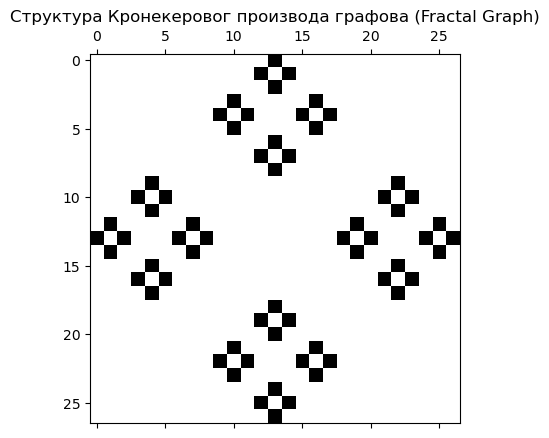

In [21]:
# Матрица суседства за једноставан граф (путања од 3 чвора)
G = np.array([[0, 1, 0], 
              [1, 0, 1], 
              [0, 1, 0]])

# Генерисање Кронекеровог производа (граф G са самим собом 3 пута)
G_large = G
for _ in range(2):
    G_large = np.kron(G_large, G)

plt.spy(G_large)
plt.title("Структура Кронекеровог производа графова (Fractal Graph)");

***

### Векторизација матрица и Кронекеров производ

Векторизација матрице значи навођење елемената те матрице унутар једног вектора колоне. Том приликом се елементи дуж колона матрице редом ређају у резултујући вектор. На примеру матрице димензије $2\times 2$ то би значило следеће пресликавање
$$\begin{bmatrix}a&b\\c&d\end{bmatrix}\quad\mapsto\quad 
\begin{bmatrix}a\\c\\b\\d\end{bmatrix}.
$$
На сличан начин се може дефинисати векторизација матрица дуж врста.
$$\begin{bmatrix}a&b\\c&d\end{bmatrix}\quad\mapsto\quad 
\begin{bmatrix}a&b&c&d\end{bmatrix}.
$$

**Пример 9.** За векторизацију матрица могу се користити различите опције библиотеке Numpy. Једну такву опцију даје метод `reshape` или истоимена рутина. Друга опција је индексирање. Упознаћемо својства ових опција на конкретном примеру мале матрице.

Приметимо да стандардна опција `reshape` врши векторизацију дуж врста матрице. Димензије излаза се уобичајено дефинишу навођењем вредности аргумената овог метода.

In [22]:
A=np.array([[1,2],[3,4]])
A.reshape(4) #u slucaju 1d izlaza

array([1, 2, 3, 4])

In [23]:
A.reshape(4,1) #u slucaju 2d izlaza

array([[1],
       [2],
       [3],
       [4]])

За векторизацију дуж колона можемо да користимо транспоновање и `reshape` или додатни аргумент као што приказује наредна кодна ћелија.

In [24]:
A.reshape(4,1,order='F')

array([[1],
       [3],
       [2],
       [4]])

In [25]:
A.reshape(4,order='F')

array([1, 3, 2, 4])

In [26]:
A.T.reshape(4,1) , A.T.reshape(4)

(array([[1],
        [3],
        [2],
        [4]]),
 array([1, 3, 2, 4]))

Параметар `order` одређује редослед којим се елементи ваде из оригиналне матрице и смештају у нови облик (у овом случају, у вектор).

##### 1. Опција `order='C'` (C‑style)

**Шта значи:** То је подразумевана (default) опција у NumPy‑у. Названа је по језику C.  
**Принцип:** Матрица се чита ред по ред (*row‑major*).  
**Резултат:** За матрицу  
$$
A = \begin{bmatrix}
1 & 2 \\
3 & 4
\end{bmatrix}
$$
процес иде: узми први ред (1, 2), па допиши други ред (3, 4).  

**Вектор:**  
$$[1,\, 2,\, 3,\, 4]$$

##### 2. Опција `order='F'` (Fortran‑style)

**Шта значи:** Названа је по језику Fortran.  
**Принцип:** Матрица се чита колона по колону (*column‑major*).  
**Резултат:** За исту матрицу \(A\), процес иде: узми прву колону (1, 3), па допиши другу колону (2, 4).  

**Вектор:**  
$$[1,\, 3,\, 2,\, 4]$$

##### Значење

У математици, стандардна дефиниција оператора векторизације  
$$\mathrm{vec}(A)$$  
јесте управо слагање елемената колона по колону.  

Дакле, ако желите **математички исправну векторизацију**, користићете: `order='F'`

***

Уводимо дефиницију операције $vec$ у општем случају. Aко је матрица $A\in\mathcal{M}_{m\times n}$ са елементима и колонама
$$A=\left[\begin{array}{c|c|c|c}
a_{00}&a_{01}&\dots&a_{0\,n-1}\\
a_{10}&a_{11}&\dots&a_{1\,n-1}\\
\vdots&\vdots&&\vdots\\
a_{m-1\,0}&a_{m-1\,1}&\dots&a_{m-1\,n-1}
\end{array}\right]
=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}\\
A_0&A_1&\dots&A_{n-1}\\
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}
\end{array}\right]-$$
Тада је векторизована (дуж колона) матрица $A$ дата са
$$vec(A)\stackrel{Деф.}{=}\left[\begin{array}{c}
A_0\\\hline A_1\\\hline \vdots\\\hline A_{n-1}
\end{array}\right]=\left[\begin{array}{c}
a_{00}\\a_{10}\\\vdots\\a_{m-1\,0}\\ \vdots\\a_{0\,n-1}\\a_{1\,n-1}\\\vdots\\ a_{m-1\,n-1}
\end{array}
\right].$$
Векторизовану верзију матрице $A\in\mathcal{M}_{m\times n}$ означаваћемо $vec(A)\in\mathcal{M}_{mn\times 1}.$

У конволуционим неуронским мрежама, након слојева који обрађују слику као матрицу, често следи Flatten слој (или нека друга операција агрегације). Овај слој  трансформише дводимензионалне просторне карактеристике у једнодимензионални вектор који се затим прослеђује потпуно повезаном (Dense) слоју. **Напомена:** Иако се у математичкој теорији под $vec(A)$ подразумева слагање колона (због увреженог договора да су колоне вектори, F-style), већина библиотека за машинско учење (као што су PyTorch и TensorFlow) приликом операције Flatten користи слагање дуж врста (C-style). Међутим, концептуална улога остаје иста: трансформација дводимензионалних просторних карактеристика у једнодимензионални вектор.

***

**Теорема 3.** За векторизовану матрицу важе следеће особине:
1. $(\forall v\in\mathcal{M}_{n\times 1})\quad vec(v)=vec(v^T)=v.$
1. $(\forall v\in\mathcal{M}_{n\times 1})(\forall u\in\mathcal{M}_{m\times 1})\quad vec(vu^T)=u\otimes v.$
1. $(\forall \alpha,\beta\in\mathbb{C})(\forall A,B\in\mathcal{M}_{m\times n})\quad 
vec(\alpha A+\beta B)=\alpha\, vec(A)+\beta\, vec(B).$

Доказе ових особина остављамо као лаку вежбу.

***

**Задатак 8.** Нека су $A,B\in\mathcal{M}_{m\times n}.$ Доказати да је тада
$${\rm tr(A^TB)}=vec(A)^T\,vec(B).$$

**Решење:**

Увођењем ознака елемената матрица $A=[a_{ij}]_{m\times n}$ и $B=[b_{ij}]_{m\times n},$ имамо
\begin{align}
A^TB&=\left[\sum_{k\in(m)} a_{ki}b_{kj}\right]_{n\times n},\\
{\rm tr}(A^TB)&=\sum_{j\in(n)}\sum_{k\in(m)} a_{kj}b_{kj},\\
vec(A)^T\,vec(B)&=\sum_{j\in(n)}A(:,j)^TB(:,j)=\sum_{j\in(n)}\sum_{k\in(m)} a_{kj}b_{kj}.
\end{align}

***

**Пример 10.** Нека су $A\in\mathcal{M}_{m\times n}$ и $B\in\mathcal{M}_{n\times m}$ матрице код којих је могућ производ у оба смера, $AB$ и $BA.$  Посматрамо прво производ $AB\in\mathcal{M}_{m\times m}.$ Модуларност матричног множења по колонама друге матрице:
$$A\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&\phantom{W}&\phantom{W}\\
B_0&B_1&\dots&B_{m-1}\\\phantom{W}&\phantom{W}&\phantom{W}&\phantom{W}
\end{array}\right]=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&\phantom{W}&\phantom{W}\\
AB_0&AB_1&\dots&AB_{m-1}\\\phantom{W}&\phantom{W}&\phantom{W}&\phantom{W}
\end{array}\right]$$
може да се искаже кроз операције које смо обрадили до сада,
$$vec(AB)=(I_m\otimes A)vec(B).$$

Интересантно је проверити и производ $(A^T\otimes I_m)vec(B):$
\begin{align}
(A^T\otimes I_m)vec(B)&=\begin{bmatrix}
a_{00}I_m&a_{10}I_m&\dots&a_{m-10}I_m\\
a_{01}I_m&a_{11}I_m&\dots&a_{m-11}I_m\\
\vdots&\vdots&&\vdots\\
a_{0n-1}I_m&a_{1n-1}I_m&\dots&a_{m-1n-1}I_m
\end{bmatrix}
\begin{bmatrix}B_0\\B_1\\\vdots\\B_{m-1}\end{bmatrix}\\
&=\begin{bmatrix}
a_{00}B_0+a_{10}B_1+\dots+a_{m-10}B_{m-1}\\
a_{01}B_0+a_{11}B_1+\dots+a_{m-11}B_{m-1}\\
\vdots\\
a_{0n-1}B_0+a_{1n-1}B_1+\dots+a_{m-1n-1}B_{m-1}
\end{bmatrix}=vec(BA).
\end{align}

Слично, модуларност множења по врстама прве матрице
$$A^TB=\begin{bmatrix}\phantom{W}&A_0^T&\phantom{W}\\\hline
\phantom{W}&A_1^T&\phantom{W}\\\hline &\vdots&\\\hline
\phantom{W}&A_m^T&\phantom{W}
\end{bmatrix}B=\begin{bmatrix}\phantom{W}&A_0^TB&\phantom{W}\\\hline
\phantom{W}&A_1^TB&\phantom{W}\\\hline &\vdots&\\\hline
\phantom{W}&A_m^TB&\phantom{W}
\end{bmatrix},$$
можемо да запишемо и на следећи начин:
$$vec((A^TB)^T)=vec(B^TA)=(I\otimes B^T)vec (A)=(I\otimes B)^Tvec (A).$$
Приметимо да је $vec((A^TB)^T)$ векторизација дуж врста матрице $A^TB.$

У наставку се бавимо једнакостима сличног типа.

***

**Задатак 9.** Нека су дате три квадратне матрице $A,B,C\in\mathcal{M}_{n\times n}$ и означимо са $vec(B)$  векторизацију матрице $B$ дуж колона. Показати једнакост
$$vec(ABC)=(C^T\otimes A)\,vec(B).$$

**Решење :**

Искористићемо доказане једнакости у примеру 10.
\begin{align}
vec(ABC)&=vec(A(BC))=(I\otimes A)vec(BC)=(I\otimes A)(C^T\otimes I)vec(B)\\
&=(IC^T)\otimes(AI)vec(B)=(C^T\otimes A)vec(B).
\end{align}

**2. начин:** Уведимо ознаке колона матрица $B$ и $C,$
\begin{align}
B&=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}\\
B_0&B_1&\dots&B_{n-1}\\
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}
\end{array}\right]
\quad\Longrightarrow\quad
vec(B)=\left[\begin{array}{c}
B_0\\\hline B_1\\\hline \vdots\\\hline B_{n-1}
\end{array}
\right]
,
\\
C&=\left[\begin{array}{c|c|c|c}
c_{00}&c_{01}&\dots&c_{0\,n-1}\\
c_{10}&c_{11}&\dots&c_{1\,n-1}\\
\vdots&\vdots&&\vdots\\
c_{n-1\,0}&c_{n-1\,1}&\dots&c_{n-1\,n-1}
\end{array}\right]
=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}\\
C_0&C_1&\dots&C_{n-1}\\
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}
\end{array}\right]\\
&\quad\Longrightarrow\quad
C^T=\left[\begin{array}{c}
\phantom{WW}C_0^T\phantom{WW}\\\hline
\phantom{WW}C_1^T\phantom{WW}\\\hline
\vdots\\\hline
\phantom{WW}C_{n-1}^T\phantom{WW}
\end{array}
\right],\\
C^T\otimes A&=\left[\begin{array}{c}
\phantom{W}C_0^T\otimes A\phantom{W}\\\hline
\phantom{W}C_1^T\otimes A\phantom{W}\\\hline
\vdots\\\hline
\phantom{W}C_{n-1}^T\otimes A\phantom{W}
\end{array}
\right]\quad\Longrightarrow\quad
(C^T\otimes A)\,vec(B)=\left[\begin{array}{c}
(C_0^T\otimes A)\,vec(B)\\\hline
(C_1^T\otimes A)\,vec(B)\\\hline
\vdots\\\hline
(C_{n-1}^T\otimes A)\,vec(B)
\end{array}
\right]
.
\end{align}

\begin{align}
(C_i^T\otimes A)\,vec(B)&=\begin{bmatrix}c_{0i}A&c_{1i}A&\dots&c_{n-1\,i}A\end{bmatrix}
\left[\begin{array}{c}
B_0\\\hline B_1\\\hline \vdots\\\hline B_{n-1}
\end{array}
\right]\\
&=c_{0i}\underbrace{AB_0}_{\mbox{прва колона матрице }AB}+c_{1i}\underbrace{AB_1}_{\mbox{друга колона матрице }AB}
+\dots+c_{n-1\,i}\underbrace{AB_{n-1}}_{n\mbox{-та колона матрице }AB}\\
&=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}\\
AB_0&AB_1&\dots&AB_{n-1}\\
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}
\end{array}\right]
\begin{bmatrix}c_{0i}\\c_{1i}\\\vdots\\c_{n-1\,i}\end{bmatrix}=\underbrace{ABC_i}_{i\mbox{-та колона матрице }ABC}
\end{align}

Закључујемо да матрица $(C^T\otimes A)\,vec(B)$ садржи поређане колоне матрице $ABC.$ Тиме је доказано да је $vec(ABC)=(C^T\otimes A)\,vec(B).$

***

С обзиром да се векторизација може спроводити дуж врста или колона матрице погодно је увести ознаке које ће то подржати. У складу са `axis` ознакама Python наредби за рад са вишедимензионалним низовима означаваћемо векторизацију дуж врста са $B_{[0]},$ а дуж колона са $B_{[1]}$ (`axis=0`  row-major, `axis=1` column-major).  Тада претходну једнакост записујемо у облику
$$(ABC)_{[1]}=(C^T\otimes A)\,B_{[1]}.$$
Слично претходној формули, за векторизацију дуж врста имамо:
$$(ABC)_{[0]}=(C^TB^TA^T)_{[1]}=(A\otimes C^T)\,B_{[1]}^T=(A\otimes C^T)\,B_{[0]}.$$

Упоредите ове једнакости са оним анализираним у примеру 10 ($C=I$).

Наведена веза множења је центар ефикасних израчунавања у великим мрежама. Наредним примером показаћемо уштеду у времену.

In [27]:
m, n, p, q = 100, 100, 100, 100
A = np.random.randn(m, n)
B = np.random.randn(p, q)
x = np.random.randn(n*q, 1)

# Наивно множење: (A ⊗ B) @ x
start_naive = timer()
W = np.kron(A, B)
res1 = W @ x
end_naive = timer()
print(f"Naivno vreme: {end_naive - start_naive:.4f}s")

# Ефикасно множење vec(AXB) = (B.T ⊗ A)vec(X)
# Третирамо x као vec(X), због тога формирамо X
start_kron = timer()
X_mat = x.reshape(q, n).T 
res2_mat = B @ X_mat @ A.T # primena formule
res2 = res2_mat.T.reshape(-1, 1) # nazad u vektor
end_kron = timer()
print(f"Efikasno vreme: {end_kron - start_kron:.4f}s")
print(f"Faktor ubrzanja: {(end_naive - start_naive) / (end_kron - start_kron):.2f}x")

Naivno vreme: 0.6731s
Efikasno vreme: 0.0301s
Faktor ubrzanja: 22.37x


In [28]:
np.all(np.isclose(res1,res2))

True

***

Један од примера примене једнакости из задатка 9 је израчунавање дискретне Фуријеове трансформације над дводимензионалним низовима. То ће бити једна од наредних тема. У наредном примеру показујемо кључно својство сепарабилности на другој врсти трансформације: Гаусов филтер.

**Пример 11.** Гаусов филтер је један од најважнијих алата у обради слика, а његова ефикасност директно почива на својству **сепарабилности**. Дводимензионална Гаусова функција дефинисана је као:
$$G(x, y) = \frac{1}{2\pi\sigma^2} e^{-\frac{x^2 + y^2}{2\sigma^2}}$$
Захваљујући својству експоненцијалне функције, она се може разбити на производ две једнодимензионалне функције:
$$G(x, y) = \left( \frac{1}{\sqrt{2\pi}\sigma} e^{-\frac{x^2}{2\sigma^2}} \right) \cdot \left( \frac{1}{\sqrt{2\pi}\sigma} e^{-\frac{y^2}{2\sigma^2}} \right) = g(x) \cdot g(y).$$

Да бисмо применили Гаусов филтер на дигиталну слику, морамо извршити **дискретизацију** непрекидне функције. То значи узорковање ове функције на дискретној мрежи тачака како би се добила матрица тежина (кернел). 
1. Дефинишемо прозор димензије $d \times d$ (обично је $d$ непаран број, нпр. $d=2k+1$).
2. Узоркујемо вредности на целобројним координатама $t \in \{-k, \dots, 0, \dots, k\}$.
3. Вредност дискретног 1D вектоpa $g$ у тачки $n$ износи:
$$g[n] = \frac{1}{\sqrt{2\pi}\sigma} e^{-\frac{n^2}{2\sigma^2}}.$$

Дискретизација уводи грешку јер се вредности изван прозора $d$ одбацују. Да би филтер сачувао укупну енергију (осветљај) слике, збир свих елемената кернела мора бити тачно 1:
$$g_{norm} = \frac{g}{\sum g}.$$

Захваљујући једнакости $G(x_i, y_j) =g(x_i) \cdot g(y_j)$ , матрицу $K=[G(x_i,y_j)]$ добијамо као **Кронекеров производ** (или спољашњи производ) два нормализована 1D вектора:
$$K = g_{norm} \otimes g_{norm}^T = g_{norm} g_{norm}^T.$$
То зовемо **сепарабилност**. Матрица ранга 1 је увек сепарабилна. У теореми 3, особина 2, показали смо да за $K =g_{norm} g_{norm}^T$ ранга 1 важи 
$$vec(K)=g\otimes g.$$

Претпоставимо да је дата велика матрица података $M$ (нпр. gray-scale слика) Филтер $K$ је обично матрица мале димензије која се клизно примењује на подматрице од $M$ које су исте димензије - печеве $P.$ Примена филтера је израчунавање Фробенијусовог склаарног производа $\langle K,P\rangle_F={\rm tr}(K^TP).$

.Као што је показано у задатку 8, важи:
\begin{align}
{\rm tr}(K^TP)&=vec(K)^Tvec(P)=(g\otimes g)^Tvec(P)=(g^T\otimes g^T)vec(P)\\
&\stackrel{Зад.9.}{=}vec(g^TPg)=g^TPg.
\end{align}

Због асоцијативности матричног множења видимо да је свеједно хоћемо ли 1D Гаусов филтер примењивати прво редом на врсте или колоне печа $P.$

У пракси (PyTorch, TensorFlow, CUDA), конволуција се скоро никада не ради „клизањем” кроз петље, јер је то споро. Користи се алгоритам **im2col (image to column)** који операцију преводи у чист матрични производ:

**Реструктурирање слике:**  
Сви могући блокови слике (patches) на које кернел може да делује се извуку и постану колоне једне велике привремене матрице $X_{\text{колоне}}.$ Ако је кернел димензије $d\times d$ то значи да се сваки пиксел слике понови $d^2$ пута. То чини матрицу $X_{\text{колоне}}$ ужасно великом.

**Реструктурирање филтера:**  
Кернел се исправи у један вектор‑врсту $K_{\text{врста}}$ дужине $d^2.$

**Матрично множење:**  
Цела конволуција се тада извршава као једно велико матрично множење:
$$
Y = K_{\text{врста}} \cdot X_{\text{колооне}}
$$

Сепарабилност матрице $K$ служи да се описана процедура изврши у два знатно једноставнија корака, чиме се меморијски затеви у сваком кораку смањују за фактор $d.$ Користи се једнодимензионални вектор филтер. Уместо квадратних блокова, из слике се извлаче само једнодимензионални печеви (сегменти) дуж сваке колоне. Тако се формира матрица  $X_{\text{1D-колоне}}$ која сваки пиксел понавља $d$ пута. Број врста ове матрице је само $d.$ Применом 1D филтера $g^T$ добијамо међурезултат:
$$Y=g^TX_{\text{1D-колоне}}.$$
Матрица $Y$ се реструктуира у $Y_{\text{1D-врсте}}$ тако што се сада врсте деле на печеве дужине $d.$ Поново се сваки пиксел трансформисане слике понавља $d$ пута. Поновном применом филтера добијамо коначан резултат:
$$T=g^TY_{\text{1D-врсте}}.$$
Матрица $T$ се потом реструктуира натраг у формат слике.

На овај начин, сепарабилност директно решава уско грло меморије: уместо да сваки пиксел шетамо кроз меморију $d^2$ пута, ми га процесирамо кроз два пролаза од по $d$ пута, што за веће филтере омогућава убрзања и од неколиko десетина пута.

In [29]:
from scipy.ndimage import gaussian_filter1d
from scipy.signal import convolve2d

In [30]:
d = 15          # димензија прозора (радијус је 7)
sigma = 2.0     # стандардна девијација
k = d // 2

# Дискретни координатни простор
t = np.arange(-k, k + 1)

# 1. Израчунавање вредности (Дискретизација)
g = (1.0 / (np.sqrt(2 * np.pi) * sigma)) * np.exp(-t**2 / (2 * sigma**2))

# 2. Нормализација (да збир буде 1)
g /= g.sum()
g_1d = g.reshape(-1, 1) # вектор колона

# 3. Конструкција 2D кернела преко Кронекеровог производа
K_2d = g_1d @ g_1d.T 

# --- ДЕМОНСТРАЦИЈА ЕФИКАСНОСТИ ---
n = 1000
X = np.random.rand(n, n)

# Стандардна 2D конволуција (O(d^2))
start = timer()
res_naive = convolve2d(X, K_2d, mode='same')
vreme_naive = timer() - start

# Сепарабилна конволуција (O(2d)) - секвенцијална примена по осама
start = timer()
# Користимо идентитет да се 2D филтрирање може разбити на два 1D пролаза
res_sep = gaussian_filter1d(X, sigma=sigma, axis=0) # оса 0 (врсте)
res_sep = gaussian_filter1d(res_sep, sigma=sigma, axis=1) # оса 1 (колоне)
vreme_sep = timer() - start

print(f"Време 2D конволуције: {vreme_naive:.4f}s")
print(f"Време сепарабилне:    {vreme_sep:.4f}s")
print(f"Убрзање: {vreme_naive/vreme_sep:.1f}x")

Време 2D конволуције: 0.4307s
Време сепарабилне:    0.0180s
Убрзање: 24.0x


***

Упознаћемо и предности Кронекеровог производа кроз слојеве неуронских мрежа.

**Пример 12.** У стандардним неуронским мрежама, слој је дефинисан матрицом тежина $W.$ Када су те матрице огромне (нпр. у језичким моделима), користимо матрицу слоја дефинисану као  
$$
W = A \otimes B.
$$ 
Ово представља својеврсну компресију слојева.  Трансформација улаза $x$ (који посматрамо као векторизовану матрицу података $vec(X)$) не захтева експлицитно конструисање огромне матрице $W.$  Уместо тога, операција се (на основу задатка 9) може разбити на два независна, секвенцијална множења мањим матрицама $A$ и $B,$ примењена на реструктурирани улаз $x$ у $X,$ 
$$
W x = (A \otimes B)\,{vec}(X) = {vec}(B X A^{T})
$$

Приметимо да је ово идентична логика коју смо користили код сепарабилног Гаусовог филтера. Операција се разбија на два независна, секвенцијална множења мањим матрицама $A$ и $B$, примењена на реструктурирани улаз $X$. Тиме се рачунска сложеност драстично смањује, а меморијски захтеви за чување тежина падају са  
$O(m^2 n^2)$ на $O(m^2 + n^2)$.

Ова формула се користи за извођење **Јакобијана сложених функција**.  
Ако посматрамо линеарни слој
$$
Y = WX,
$$
где је $W$ матрица тежина, а $X$ улазни подаци, градијент функције губитка у односу на тежине много се лакше израчунава ако се цела једначина **векторизује**. Коришћењем идентитета:
$$
{vec}(ABC) = (C^{T} \otimes A)\,{vec}(B).
$$
можемо представити промену излаза у зависности од промене тежина као чист Кронекеров производ, што је основа за ефикасне алгоритме оптимизације другог реда, попут K-FAC (Kronecker-factored Approximate Curvature).

Без овог идентитета, било би скоро немогуће ефикасно имплементирати градијентни спуст за велике матрице, јер би:
- сваки корак захтевао ручно „расплитање“ индекса,
- изрази за Јакобијан били огромни,
- имплементација била спора и склона грешкама.

Уместо тога, векторизација омогућава да:
- цео линеарни слој третирамо као једну велику линеарну трансформацију,
- градијент $\frac{\partial L}{\partial W}$ добијемо применом Кронекеровог производа,
- израчунавање буде оптимизовано за GPU/TPU архитектуре.

Зато је идентитет
$$
{vec}(ABC) = (C^{T} \otimes A)\,{vec}(B)
$$
један од најважнијих алата у модерној примењеној линеарној алгебри и основа ефикасног тренинга великих неуронских мрежа.

***

**Задатак 10.** Ако је производ $ABCD$ добро дефинисан и представља квадратну матрицу, показати једнакост
$${\rm tr}(ABCD)=({vec}(D))^T(A\otimes C^T)\, {vec}(B^T).$$

**Решење :**

На основу доказаног у задатку 8, ${\rm tr(X^TY)}=vec(X)^T\,vec(Y)=vec(Y)^T\,vec(X),$ 

као и показаног у задатку 9, 
$vec(XYZ)=(Z^T\otimes X)\,vec(Y),$ имамо

\begin{align}
{\rm tr}(ABCD)&=(vec D)^T\,vec((ABC)^T)=(vec D)^T\,vec(C^TB^TA^T)\\
&=(vec{D})^T(A\otimes C^T)\, vec(B^T).
\end{align}

Овај идентитет је изузетно важан у статистици и машинском учењу, нарочито при раду са квадратним формама и Гаусовим расподелама. Он нам омогућава да отпакујемо траг производа матрица у линеарну комбинацију њихових векторизованих облика, што је кључни корак при извођењу градијената сложених функција губитка.

***

**Пример 13.** Разматрамо случај сагласног система линеарних једначина где је матрица система дата у облику Кронекеровог производа две матрице,
$$(A\otimes B)x=y,\qquad A\in\mathcal{M}_{m\times n},\ B\in\mathcal{M}_{p\times q},\ x\in\mathcal{M}_{nq\times 1},\ y\in\mathcal{M}_{mp\times 1}.$$

Под претпоставком да су познате матрице $A$ и $B,$ и да су матрице великих димензија, њихов Кронекеорв производ $A\otimes B$ ће бити огромна матрица. Поставља се природно питање да ли постоји начин решавања датог система а да се матрица $A\otimes B$ експлицитно не израчунава?

У сврхе налажења оваквог решења уведимо партиције вектора колона (блок векторе):
\begin{align}
x&=\begin{bmatrix}x_0\\x_1\\\vdots\\x_{n-1}\end{bmatrix},\qquad x_i\in\mathcal{M}_{q\times 1}\\
y&=\begin{bmatrix}y_0\\y_1\\\vdots\\y_{m-1}\end{bmatrix},\qquad y_j\in\mathcal{M}_{p\times 1}
\end{align}

Систем једначина у блок форми тада гласи
$$\begin{bmatrix}a_{00}B&a_{01}B&\dots&a_{0\,n-1}B\\
a_{10}B&a_{11}B&\dots&a_{1\,n-1}B\\
\vdots&\vdots&&\vdots\\
a_{m-1\,0}B&a_{m-1\,1}B&\dots&a_{m-1\,n-1}B\end{bmatrix}
\begin{bmatrix}x_0\\x_1\\\vdots\\x_{n-1}\end{bmatrix}=
\begin{bmatrix}y_0\\y_1\\\vdots\\y_{m-1}\end{bmatrix}.$$
Том приликом је 
\begin{align}
y_j&=\begin{bmatrix}a_{j0}B&a_{j1}B&\dots&a_{j\,n-1}B\end{bmatrix}
\begin{bmatrix}x_0\\x_1\\\vdots\\x_{n-1}\end{bmatrix}=a_{j0}Bx_0+a_{j1}Bx_1+\dots+a_{j\,n-1}Bx_{n-1}\\
&=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}\\
Bx_0&Bx_1&\dots&Bx_{n-1}\\
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}
\end{array}\right]
\begin{bmatrix}a_{j0}\\a_{j1}\\\vdots\\a_{j\,n-1}\end{bmatrix}
=B\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}\\
x_0&x_1&\dots&x_{n-1}\\
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}
\end{array}\right]
\begin{bmatrix}a_{j0}\\a_{j1}\\\vdots\\a_{j\,n-1}\end{bmatrix}
\end{align}

Када уведемо ознаку матрице непознатих $X=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}\\
x_0&x_1&\dots&x_{n-1}\\
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}
\end{array}\right]$ и матрице слободних чланова $Y=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}\\
y_0&y_1&\dots&y_{m-1}\\
\phantom{W}&\phantom{W}&\phantom{WW}&\phantom{W}
\end{array}\right],$
полазни систем једначина постаје еквивалентан матричној једначини
$$BXA^T=Y.$$
За матрице непознатих и слободних чланова важи да је $vec(X)=x$ и $vec(Y)=y.$ 

Решавањем дате матричне једначине добијамо решење полазног система линеарних једначина.

**II начин:** Ако вектор $x$ посматрамо као $\mathrm{vec}(X)$, а $y$ као $\mathrm{vec}(Y)$, полазна једначина постаје:
$$
(A \otimes B)\,\mathrm{vec}(X) = \mathrm{vec}(Y)
$$
Директном применом идентитета из Задатка 9 добијамо:
$$
BXA^T=Y.
$$

Посматрајмо случај где су све матрице димензија $n \times n$. Директно решавање система  
$$(A \otimes B)x = y$$  
захтева рад са матрицом димензија $n^{2} \times n^{2}$. Класични алгоритми (нпр. Гаусова елиминација) имају сложеност  
$$\mathcal{O}\big((n^{2})^{3}\big) = O(n^{6}).$$
Решавање матричне једначине  
$$B X A^{T} = Y$$  
захтева само инверзију малих матрица и њихово множење, што има сложеност  
$$O(n^{3}).$$
За матрице димензије $100 \times 100$, ово је разлика између билион ($10^{12}$) и милион ($10^{6}$) операција. Ово је разлог зашто је Кронекеров производ незаменљив у модерној нумеричкој анализи.

***

У наставку се бавимо операцијама базираним на Кронекеровом производу матрица.

***

## Кронекерова сума матрица

**Дефиниција 3.** Нека су $A=[a_{ij}]\in\mathcal{M}_{m\times m}$ и $B=[b_{kl}]\in\mathcal{M}_{n\times n}$ две квадратне матрице. Кронекерова сума $\oplus$ матрица $A$ и $B$ је матрица димензије $mn\times mn$ дата изразом:
$$A\oplus B=A\otimes I_n+I_m\otimes B.$$

Израз Кронекеровог збира кроз елементе матрица гласи:
\begin{align}
A\oplus B&=A\otimes I_n+I_m\otimes B
=\begin{bmatrix}
a_{00}I_n&a_{01}I_n&\dots&a_{0\,m-1}I_n\\
a_{10}I_n&a_{11}I_n&\dots&a_{1\,m-1}I_n\\
\vdots&\vdots&&\vdots\\
a_{m-1\,0}I_n&a_{m-1\,1}I_n&\dots&a_{m-1\,m-1}I_n
\end{bmatrix}+
\begin{bmatrix}
B&O&\dots&O\\O&B&\dots&O\\
\vdots&\vdots&&\vdots\\
O&O&\dots&B
\end{bmatrix}\\[8pt]
&=\begin{bmatrix}
B+a_{00}I_n&a_{01}I_n&\dots&a_{0\,m-1}I_n\\
a_{10}I_n&B+a_{11}I_n&\dots&a_{1\,m-1}I_n\\
\vdots&\vdots&&\vdots\\
a_{m-1\,0}I_n&a_{m-1\,1}I_n&\dots&B+a_{m-1\,m-1}I_n
\end{bmatrix}
\end{align}

Специјално, нека је $A=[a_{ij}]\in\mathcal{M}_{n\times n}.$ Тада је
\begin{align}
A\oplus A&=A\otimes I_n+I_n\otimes A=\begin{bmatrix}
A+a_{00}I_n&a_{01}I_n&\dots&a_{0\,n-1}I_n\\
a_{10}I_n&A+a_{11}I_n&\dots&a_{1\,n-1}I_n\\
\vdots&\vdots&&\vdots\\
a_{n-1\,0}I_n&a_{n-1\,1}I_n&\dots&A+a_{n-1\,n-1}I_n
\end{bmatrix}
\end{align}

***

**Пример 14.** Нека су $A=Q_AD_AQ_A^T\in\mathcal{M}_{m\times m},$ $B=Q_BD_BQ_B^T\in\mathcal{M}_{n\times n}$  спектралне декомпозиције симетричних матрица $A$ и $B.$ Тада је $A\oplus B=(Q_A\otimes Q_B)(D_A\oplus D_B)(Q_A\otimes Q_B)^T$ спектрална декомпозиција њихове Кронекерове суме.

\begin{align}
A\oplus B&=A\otimes I_n+I_m\otimes B\\
&=(Q_AD_AQ_A^T)\otimes(Q_BI_nQ_B^T)+(Q_AI_mQ_A^T)\otimes(Q_BD_BQ_B^T)\\
&=(Q_A\otimes Q_B)(D_A\otimes I_n)(Q_A\otimes Q_B)^T+(Q_A\otimes Q_B)(I_m\otimes D_B)(Q_A\otimes Q_B)^T\\
&=(Q_A\otimes Q_B)(D_A\otimes I_n+I_m\otimes D_B)(Q_A\otimes Q_B)^T\\
&=(Q_A\otimes Q_B)(D_A\oplus D_B)(Q_A\otimes Q_B)^T.
\end{align}

Сопствене вредности Кронекерове суме $A \oplus B$ једнаке су збиру свих могућих комбинација сопствених вредности матрица $A$ и $B$:
$$
\lambda_{i,j}(A \oplus B) = \lambda_i(A) + \lambda_j(B).
$$
Ово је аналогија са Кронекеровим производом, где се сопствене вредности множе.

***

**Пример 15.** Кронекерова сума се природно појављује у дефинисању Лапласијана на графовима који настају као [Декартов производ графова](https://en.wikipedia.org/wiki/Cartesian_product_of_graphs).  
Типичан пример су **мреже сензора које се развијају у времену**, где имамо:
- просторну структуру (граф сензора),
- временску структуру (линијски или циклични граф),
- а укупан граф је њихов производ.

У теорији графова, Кронекерова сума матрица суседства директно одговара **Декартовом производу графова**.  
Ако имамо два графа $G$ и $H$, њихов Декартов производ $G \,\square\, H$ има матрицу суседства:
$$
A_{G \square H}
= A_G \oplus A_H
= A_G \otimes I_n + I_m \otimes A_H.
$$

Овде:
- $A_G$ и $A_H$ су матрице суседства графова $G$ и $H$,
- $I_m$ и $I_n$ су јединичне матрице одговарајућих димензија,
- $\otimes$ је Кронекеров производ,
- $\oplus$ је Кронекерова сума.

Интуитивно разумевање: 2D решетка (grid)

Ово је најлакше разумети кроз пример **креирања дводимензионалне решетке**.

Замислите да имате линијски граф (путању) $P_n$ са $n$ чворова.  
Ако извршите Кронекерову суму тог графа са самим собом:
$$
P_n \,\square\, P_n,
$$
добијате **квадратну мрежу** (2D grid) димензија $n \times n$.

Интерпретација:
- први фактор $P_n$ контролише „редове“ мреже,
- други фактор $P_n$ контролише „колоне“,
- Кронекерова сума комбинује локалне суседности у сваком правцу независно.

Тако се једноставна структура једнодимензионалне путање претвара у дводимензионалну решетку — што је основни пример како се графови могу пренети у више димензија помоћу Кронекерове суме.

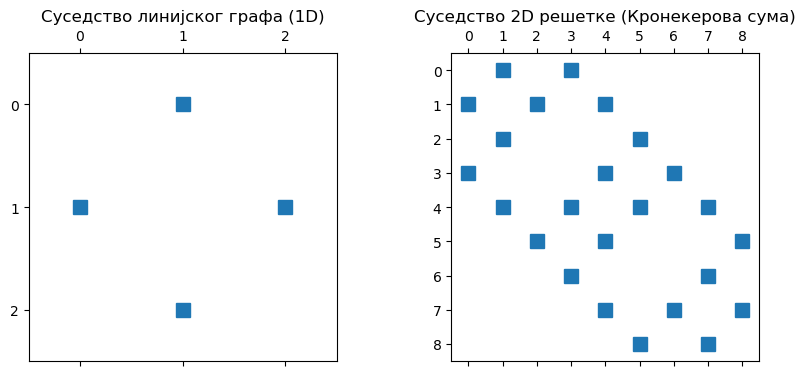

In [31]:
# Матрица суседства за линијски граф од 3 чвора (0-1-2)
A_line = np.array([[0, 1, 0], 
                   [1, 0, 1], 
                   [0, 1, 0]])

# Кронекерова сума: Креирање 2D мреже 3x3 (укупно 9 чворова)
# Сваки чвор је сада повезан са својим суседима по "x" и "y" оси
A_grid = np.kron(A_line, np.eye(3)) + np.kron(np.eye(3), A_line)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.spy(A_line, markersize=10)
plt.title("Суседство линијског графа (1D)")

plt.subplot(1, 2, 2)
plt.spy(A_grid, markersize=10)
plt.title("Суседство 2D решетке (Кронекерова сума)");

Ова конструкција је кључна јер:
- омогућава да се спектар графа производа добије као збир сопствених вредности појединачних графова,
- поједностављује анализу дифузије, топлотних процеса и динамике на графовима,
- омогућава ефикасно рачунање оператора на великим графовима користећи мале матрице.

У моделима као што су **динамичке мреже сензора**, Лапласијан графа производа описује како се информација шири и у простору и у времену, а Кронекерова сума даје формулу која је рачунски изводљива и теоријски елегантна.

#### Разлика између производа ($\otimes$) и суме ($\oplus$) у Graph ML-у

Веома је важно разликовати два начина комбиновања графова у машинском учењу, јер они имају различиту структуралну и спектралну интерпретацију. Док Кронекеров производ графова $A \otimes B$ захтева да се оба чвора „помере” истовремено (синхрони скок), Кронекерова сума $A \oplus B$ описује кретање где се у једном тренутку мења позиција само унутар једног графа, док се у другом мирује. Зато се помоћу суме граде мреже попут градских улица или сензорских решетки.

**1. Тензорски (Кронекеров) производ графова — $A \otimes B$**

У тензорском производу:
- свака интеракција из првог графа комбинује се са сваком интеракцијом из другог,
- добија се граф огромне димензије,
- структура је **самослична** (фрактална),
- користи се за моделирање и генерисање великих мрежа.

Ово је основа за **Kronecker Graph Models**, где се од мале матрице „семена“ добијају реалистични графови који имитирају:
- power-law расподелу степена,
- самосличност,
- локалне и глобалне структурне обрасце реалних мрежа.

**2. Декартов (Кронекеров) збир графова — $L_1 \oplus L_2$**

Кронекерова сума се дефинише као:
$$
L_1 \oplus L_2 = L_1 \otimes I + I \otimes L_2.
$$

Интерпретација:
- графови се „додају“ независно,
- чворови су повезани ако су повезани у једном графу, док у другом мирују,
- користи се у **Graph Signal Processing**, где желимо да раздвојимо:

  - просторне карактеристике (нпр. структура графа),
  - временске карактеристике (нпр. динамика сигнала).

Ово омогућава моделирање сложених система као комбинације више независних домена.

***

**Пример 16.** Кронекерова сума је кључна за решавање матричне једначине:
$$
AX + XB = C,
$$
познате као **Силвестерова једначина**. Применом оператора векторизације на силвестерову једначину добијамо:
$$
{vec}(A X I) + {vec}(I X B) = {vec}(C)
$$
Користећи идентитет  
$$
{vec}(A B C) = (C^{T} \otimes A)\,{vec}(B),
$$
ово постаје:
$$
(I \otimes A)\,{vec}(X) + (B^{T} \otimes I)\,{vec}(X) = {vec}(C)
$$
Извлачењем ${vec}(X)$ као заједничког фактора, добијамо Кронекерову суму:
$$
(I \otimes A + B^{T} \otimes I)\,{vec}(X)
= (B^{T} \oplus A)\,{vec}(X)
= {vec}(C).
$$
Ово омогућава да се проблем реши као **стандардни систем линеарних једначина**, што је много ефикасније за велике матрице.

#### Зашто је ово важно за AI?

**1. Стабилност контролних система**

Силвестерова једначина се јавља у анализи стабилности Љапуновљевих функција.  
Ово је критично за:
- роботске системе,
- аутономна возила,
- дронове,
- све AI системе који морају да гарантују стабилно понашање.

**2. Диференцијабилно програмирање** (енгл. differentiable programming)

У неким архитектурама неуронских мрежа — посебно:
- Continuous-time RNNs (Neural ODEs),
- Linear dynamical systems,
- State-space модели,

потребно је решити Силвестерову једначину **у сваком кораку пропагације уназад**.

То значи да је:
- Кронекерова сума,
- векторизација,
- и ефикасно решавање великих линеарних система

директно уграђено у тренинг модерних AI модела.

Кронекеров производ и Кронекерова сума су, дакле, темељни алати који повезују:
- алгебру матрица,  
- структуру графова,  
- стабилност динамичких система,  
- и диференцијабилно програмирање.

Они чине један од најдубљих мостова између математичке теорије и практичне примене у савременом машинском учењу.

***

## Катри-Рао производ матрица

**Дефиниција 4.** Нека су две матрице $A$ и $B$ дате у блок форми исте блоковске димензије $\mu\times\nu.$ Катри-Рао производ $A\star B$ је матрица блоковске димензије $\mu\times\nu$ чији су блокови једнаки Кронекеровом производу одговарајућих блокова матрица $A$ и $B.$

Нека су блок форме матрица $A=\begin{bmatrix}
A_{00} & A_{01} & \dots &A_{0\,\nu-1}\\
A_{10} & A_{11} & \dots &A_{1\,\nu-1}\\
\vdots & \vdots & \ddots & \vdots\\
A_{\mu-1\,0} & A_{\mu-1\,1} & \dots &A_{\mu-1\,\nu-1}
\end{bmatrix}$ и $B=\begin{bmatrix}
B_{00} & B_{01} & \dots &B_{0\,\nu-1}\\
B_{10} & B_{11} & \dots &B_{1\,\nu-1}\\
\vdots & \vdots & \ddots & \vdots\\
B_{\mu-1\,0} & B_{\mu-1\,1} & \dots &B_{\mu-1\,\nu-1}
\end{bmatrix},$ тада је
$$A\star B=\begin{bmatrix}
A_{00}\otimes B_{00} & A_{01}\otimes B_{01} & \dots &A_{0\,\nu-1}\otimes B_{0\,\nu-1}\\
A_{10}\otimes B_{10} & A_{11}\otimes B_{11} & \dots &A_{1\,\nu-1}\otimes B_{1\,\nu-1}\\
\vdots & \vdots & \ddots & \vdots\\
A_{\mu-1\,0}\otimes B_{\mu-1\,0} & A_{\mu-1\,1}\otimes B_{\mu-1\,1} & \dots &A_{\mu-1\,\nu-1}\otimes B_{\mu-1\,\nu-1}
\end{bmatrix}$$

***

**Пример 17.** Матрице $A=\left[\begin{array}{c|cc}
	1&2&3\\ \hline 		4&5&6\\7&8&9
	\end{array}\right]=\begin{bmatrix}A_{00}&A_{01}\\A_{10}&A_{11}\end{bmatrix}$ и $
	B=\left[\begin{array}{cc|cc}
	1&2&3&4\\ \hline 5&6&7&8\\9&10&11&12
	\end{array}\right]=\begin{bmatrix}B_{00}&B_{01}\\B_{10}&B_{11}\end{bmatrix}$ дате су у блок форми $2\times2.$ Резултат Катри-Рао производа биће исте блок форме, али су блокови далеко већих димезија.
    $$A\star B=\begin{bmatrix}A_{00}\otimes B_{00}&A_{01}\otimes B_{01}\\
    A_{10}\otimes B_{10}&A_{11}\otimes B_{11}
    \end{bmatrix}.$$

In [32]:
A=np.arange(1,10).reshape(3,3)
B=np.arange(1,13).reshape(3,4)
C00=np.kron(A[:1,:1],B[:1,:2])
C00

array([[1, 2]])

In [33]:
C01=np.kron(A[:1,1:],B[0,2:])
C01

array([[ 6,  8,  9, 12]])

In [34]:
C10=np.kron(A[1:,:1],B[1:,:2])
C10

array([[20, 24],
       [36, 40],
       [35, 42],
       [63, 70]])

In [35]:
C11=np.kron(A[1:,1:],B[1:,2:])
C11

array([[ 35,  40,  42,  48],
       [ 55,  60,  66,  72],
       [ 56,  64,  63,  72],
       [ 88,  96,  99, 108]])

In [36]:
C=np.block([[C00,C01],[C10,C11]])
C

array([[  1,   2,   6,   8,   9,  12],
       [ 20,  24,  35,  40,  42,  48],
       [ 36,  40,  55,  60,  66,  72],
       [ 35,  42,  56,  64,  63,  72],
       [ 63,  70,  88,  96,  99, 108]])

***

**Дефиниција 5.** За две матрице $A=[a_{ij}]\in\mathcal{M}_{m\times n}$ и $B=[b_{kl}]\in\mathcal{M}_{p\times n},$ са истим бројем колона, њихов Катри-Рао производ дуж колона $\odot$ је операција којом се добија матрица $C=A\odot B\in\mathcal{M}_{mp\times n},$ а чији садржај чине Кронекерови производи парова колона две матрице. 

Ако уведемо ознаке колона
$$A=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&
\phantom{WW}&\phantom{W}\\
A_0&A_1&\dots&A_{n-1}\\
\phantom{W}&\phantom{W}&
\phantom{W}&\phantom{W}
\end{array}\right],\qquad 
B=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&
\phantom{W}&\phantom{W}\\
B_0&B_1&\dots&B_{n-1}\\
\phantom{W}&\phantom{W}&
\phantom{WW}&\phantom{W}
\end{array}\right],
$$
тада су колоне матрице $C=A\odot B$ дате са:
$$C=A\odot B=A=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&
\phantom{WWW}&\phantom{W}\\
A_0\otimes B_0&A_1\otimes B_1&\dots&A_{n-1}\otimes B_{n-1}\\
\phantom{W}&\phantom{W}&
\phantom{W}&\phantom{W}
\end{array}\right].$$

***

Док Кронекеров производ „експлодира” у димензијама, Катри-Рао производ је далеко компактнији јер врши Кронекерово множење само по колонама.

***

**Пример 18.** Матрице $A=\left[\begin{array}{c|c|c}
	1&2&3\\	4&5&6\\7&8&9
	\end{array}\right]$ и $
	B=\left[\begin{array}{c|c|c}
	1&5&9\\ 2&6&10\\3&7&11\\ 4&8&12
	\end{array}\right]$ имају једнак број колона. Резултат Катри-Рао производа дуж колона је матрица са истим бројем колона, али су оне далеко већих димезија.

In [37]:
B=B.T
C=np.empty((12,3))
for i in range(3):
    C[:,i]=np.kron(A[:,i],B[:,i])
C    

array([[  1.,  10.,  27.],
       [  2.,  12.,  30.],
       [  3.,  14.,  33.],
       [  4.,  16.,  36.],
       [  4.,  25.,  54.],
       [  8.,  30.,  60.],
       [ 12.,  35.,  66.],
       [ 16.,  40.,  72.],
       [  7.,  40.,  81.],
       [ 14.,  48.,  90.],
       [ 21.,  56.,  99.],
       [ 28.,  64., 108.]])

***

Најважнија особина која чини Катри–Рао производ моћним у оптимизацији је начин на који се он понаша при множењу својом транспонованом верзијом.

**Теорема 4.** Нека су матрице $A$ и $B$ исте ширине (имају исти број колона). Тада важи:
$$
(A \,\odot\, B)^{T} (A \,\odot\, B)= (A^{T} A) \,*\, (B^{T} B),
$$
где је $\ast$ Адамаров (члан-по-члан) производ матрица.

**Доказ:**

Нека су Матрице  $A \in \mathcal{M}_{m \times n}$ и $B \in \mathcal{M}_{p \times n}$  
дате су преко својих колона:
$$A=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&
\phantom{WW}&\phantom{W}\\
A_0&A_1&\dots&A_{n-1}\\
\phantom{W}&\phantom{W}&
\phantom{W}&\phantom{W}
\end{array}\right],\qquad 
B=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&
\phantom{W}&\phantom{W}\\
B_0&B_1&\dots&B_{n-1}\\
\phantom{W}&\phantom{W}&
\phantom{WW}&\phantom{W}
\end{array}\right],
$$
тада је
$$C=A\odot B=A=\left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&
\phantom{WWW}&\phantom{W}\\
A_0\otimes B_0&A_1\otimes B_1&\dots&A_{n-1}\otimes B_{n-1}\\
\phantom{W}&\phantom{W}&
\phantom{W}&\phantom{W}
\end{array}\right].$$

Резултат производа $C^{T} C$ је матрица димензија $n \times n.$ Означимо њен општи елемент на позицији $(i,j)$ као $G_{ij}.$ Овај елемент представља скаларни производ $i$‑те и $j$‑те колоне матрице $C$:
$$
G_{ij} = C_i^{T} C_j = (A_i \otimes B_i)^{T} (A_j \otimes B_j).
$$

Користимо две кључне особине (Теорема 2):
1. **Транспоновање** $(A \otimes B)^{T} = A^{T} \otimes B^{T}$
2. **Мешовити производ** $(A \otimes B)(C \otimes D) = (AC \otimes BD)$

Применом ових својстава:
$$
G_{ij}
= (A_i^{T} \otimes B_i^{T})(A_j \otimes B_j)
= (A_i^{T} A_j) \otimes (B_i^{T} B_j).
$$

Пошто су $A_i^{T} A_j$ и $B_i^{T} B_j$ скалари, а Кронекеров производ два скалара једнак је њиховом обичном множењу, добијамо:
$$
G_{ij} = (A_i^{T} A_j)\,(B_i^{T} B_j).
$$

Елемент матрице $A^{T} A$ на позицији $(i,j)$ је $M_{ij} = A_i^{T} A_j.$ Елемент матрице $B^{T} B$ на позицији $(i,j)$ је $N_{ij} = B_i^{T} B_j.$ Адамаров (члан‑по‑члан) производ матрица даје:
$$
\big((A^{T} A) * (B^{T} B)\big)_{ij}
    = M_{ij} \cdot N_{ij}
    = (A_i^{T} A_j)(B_i^{T} B_j).
$$
Пошто је ово идентично изразу за $G_{ij}$, следи да су целе матрице једнаке:
$$
(A \odot B)^{T} (A \odot B)= (A^{T} A) * (B^{T} B).\quad\Box
$$

Приметимо да лева страна израза захтева множење две огромне матрице димензија  $(mp \times n)$. Десна страна, међутим, захтева само множење две мале матрице и њихов Адамаров производ.
У тензорским моделима, ово својство омогућава израчунавање градијената над милионима података у милисекундама.

***

**Пример 19.** Катри–Рао производ представља **централну операцију** у CP декомпозицији тензора.  
У CP декомпозицији тензора реда 3:
$$
\mathcal{X} \approx \sum_{k=1}^{r} a_k \circ b_k \circ c_k,
$$
ажурирање фактора (нпр. матрице $A$) у [ALS](https://stanford.edu/~rezab/classes/cme323/S15/notes/lec14.pdf)(alternating least squares) алгоритму захтева управо Катри–Рао производ:
$$
A = X_{(1)} (C \odot B) \left[(C \odot B)^{T}(C \odot B)\right]^{-1}.
$$

Инверзија матрице $[(C \,\odot\, B)^{T} (C \,\odot\, B)]$  би била рачунски немогућа да морамо експлицитно формирати Катри–Рао производ.  Међутим, захваљујући Теореми 4, ми заправо рачунамо:
$$
\big[(C^{T} C) \,*\, (B^{T} B)\big]^{-1}
$$
Ово је инверзија матрице малих димензија $(r \times r)$, где је $r$ ранг декомпозиције (обично између 10 и 100), чак и ако су оригинални подаци у тензору огромни.

Ово чини Катри–Рао производ кључним за:
- ефикасно рачунање CP декомпозиције,
- рад са великим и ретким тензорима,
- примене у обради сигнала, препознавању образаца, препорукама и анализи мултимодалних података.

Због своје структуре (комбинације Кронекеровог производа по колонама) Катри–Рао производ омогућава да се CP декомпозиција изводи много ефикасније него што би то било могуће директним тензорским операцијама.

***

Још једна кључна веза са претходним поглављем је векторизација производа где је средња матрица дијагонална:
$$
\mathrm{vec}(A D B^{T}) = (B \,\odot\, A)\,\mathrm{diag}(D).
$$
Ово својство омогућава да се дијагонални „latent factors“ (скривени фактори) у моделу вежу за Катри–Рао структуру.

Нека су димензије матрица:
- $A \in \mathcal{M}_{m \times n}$
- $D \in \mathcal{M}_{n \times n},$ дијагонална матрица,  $D = \mathrm{diag}(d_0, d_1, \ldots, d_{n-1})$
- $B \in \mathcal{M}_{p \times n}$

Вектор дијагоналних елемената матрице $D$ је $ d = \mathrm{diag}(D) = \begin{bmatrix}
d_0 & d_1 &\dots &d_{n-1}\end{bmatrix}^Т.$

Из Задатка 9 знамо да важи:
$$
{vec}(X Y Z) = (Z^{T} \otimes X)\,{vec}(Y)
$$
Ако поставимо $X = A$, $Y = D$ и $Z = B^{T}$, добијамо:
$$
{vec}(A D B^{T})= \big((B^{T})^{T} \otimes A\big)\,{vec}(D)
$$
Пошто је $(B^{T})^{T} = B$, следи:
$$
{vec}(A D B^{T}) = (B \otimes A)\,{vec}(D)
$$

Пошто је $D$ дијагонална матрица димензија $n \times n$, њен векторизовани облик ${vec}(D)$ је вектор дужине $n^{2}$ који је веома ретко поседнут (sparse). Ненула елементи се налазе само на позицијама које одговарају дијагонали:
$$
{vec}(D) =\begin{bmatrix}d_0& 0& \ldots& 0& d_1& 0& \ldots& 0&\ldots&0& \ldots& 0& d_{n-1}\end{bmatrix}^T
$$
Прецизније, елемент $d_j$ се у вектору ${vec}(D)$ налази на позицији $jn + j.$

Производ матрице и вектора  $(B \otimes A)\,\mathrm{vec}(D)$ можемо посматрати као линеарну комбинацију колона матрице $(B \otimes A)$. Због структуре вектора $\mathrm{vec}(D)$, овај производ селектује само оне колоне матрице $B \otimes A$ које одговарају ненула позицијама у $\mathrm{vec}(D)$ и скалира их вредностима $d_j$:
$$(B \otimes A)\,\mathrm{vec}(D)
    = \sum_{j=0}^{n-1} d_j \cdot 
      \big(\text{колона } jn + j \text{ матрице } B \otimes A \big).
$$
Дакле:
$$
(B \otimes A)\,\mathrm{vec}(D)= \sum_{j=0}^{n-1} d_j\, (B_j \otimes A_j)
$$
где су $A_j$ и $B_j$ $j$‑те колоне матрица $A$ и $B$.

Према Дефиницији 5, Катри–Рао производ дуж колона је матрица чије су колоне управо $B_j \otimes A_j$:
$$
B \,\odot\, A
    = \left[\begin{array}{c|c|c|c}
\phantom{W}&\phantom{W}&
\phantom{WWW}&\phantom{W}\\
A_0\otimes B_0&A_1\otimes B_1&\dots&A_{n-1}\otimes B_{n-1}\\
\phantom{W}&\phantom{W}&
\phantom{W}&\phantom{W}
\end{array}\right].
$$
Множењем ове матрице вектором дијагоналних елемената  
$d = \begin{bmatrix} d_0 &\ldots& d_{n-1} \end{bmatrix}^T$  
добијамо:
$$
(B \,\odot\, A)\, d= \sum_{j=0}^{n-1} d_j\, (B_j \otimes A_j).
$$
Пошто обе стране израза дају исту суму
$$
\sum_{j=1}^{n} d_j\, (B_j \otimes A_j),
$$
доказали смо:
$$
{vec}(A D B^{T}) = (B \,\odot\, A)\, \mathrm{diag}(D).
$$

***

## Резиме

1. Слој потпуно повезане мреже (Dense / Fully Connected Layer)

У стандардним неуронским мрежама, слој је дефинисан матрицом тежина $W$. Када су те матрице огромне (нпр. у језичким моделима), користе се **Kronecker‑factored тежине** како би се број параметара драстично смањио.

Контекст: Уместо да чувамо $m \times n$ параметара матрице $W$, чувамо две много мање матрице $A$ и $B$ чији Кронекеров производ даје велику матрицу:
$$
W = A \otimes B.
$$
Ово омогућава **екстремну компресију слојева**, јер број параметара постаје:
$$
mn \quad \longrightarrow \quad (\text{dim}(A) + \text{dim}(B)) \ll mn.
$$

Математичка суштина: Уместо класичне трансформације $y = W x,$ користимо еквивалентну, али много јефтинију операцију $ Y = B X A^{T},$ где је $X$ матрица која представља улаз у облику погодном за ову факторизацију.

Уштеда у сложености: Класично множење $W x$ кошта $\mathcal{O}(n^4).$ Kronecker‑factored израз $Y = B X A^{T}$ кошта $O(n^2).$ Ово је разлог зашто се Kronecker‑factored слојеви користе у великим моделима — добија се огромна уштеда у меморији и рачунској сложености, без губитка изражајности модела.

2. Слој конволуције (Convolutional Layer)

Код конволуционих мрежа (CNN), Кронекеров производ је темељ **сепарабилних конволуција**.

Контекст: Просторни филтер $K$ може се представити као Кронекеров производ:
$$
K = g_y \otimes g_x^{T},
$$
нпр. у случају Гаусовог филтера, где се 2D филтер разлаже на производ вертикалног и хоризонталног 1D филтера.  
Ово је основа за архитектуре као што су **MobileNet** и **Xception**, које користе depthwise–separable конволуције ради уштеде рачунања.

Математичка суштина: Фробенијусов скаларни производ конволуције $\langle K,\, P \rangle_F$ постаје много јефтинији матрични производ $ g_y^{T} \, P \, g_x.$nОва трансформација претвара операцију из **memory‑bound** (доминирану приступом меморији) у **compute‑bound** (доминирану аритметиком), што је кључно за ефикасност на модерним процесорима и мобилним уређајима.

Уштеда у сложености: Класична 2D конволуција са филтером димензије $d \times d$ захтева $O(d^{2})$ операција по пикселу. Сепарабилна конволуција, заснована на Кронекеровом разлагању, захтева $O(2d),$ јер се примењују два 1D филтера. Ово представља изузетно убрзање, посебно за велике филтере и дубоке мреже.

3. Слоја пажње (Attention Layer)

У Transformer моделима (нпр. GPT), матрице пажње и њихови градијенти су масивни.

Контекст: Методе попут K-FAC (Kronecker-factored Approximate Curvature) користе идентитет инверза
$$(A \otimes B)^{-1} = A^{-1} \otimes B^{-1}$$
за апроксимацију Фишерове информационе матрице.

Математичка суштина: Инверзија огромне матрице (која би била $O(n^{6})$) своди се на инверзију две мале компоненте ($O(n^{3})$), што омогућава оптимизацију другог реда у реалном времену.

4. Рекурентни слојеви (RNN / LSTM)

Кронекерова структура помаже у контроли динамике и стабилности модела који обрађују секвенце.

Контекст: Дизајнирањем тежина као $W = A \otimes B,$ можемо гарантовати ортогоналност велике матрице ако су фактори ортогонални.

Математичка суштина: Спектрални радијус и сопствене вредности велике матрице $\lambda_{i,j} = \lambda_i \mu_j$
контролишу се искључиво кроз мале матрице фактора, спречавајући проблем „експлодирајућих градијената”.

5. Графовски и динамички слојеви (GNN / Neural ODEs) — примена Кронекерове суме

Кронекерова сума (⊕) представља основу за рад са Декартовим производима графова и сложеним динамичким системима.

Контекст: Користи се за моделирање просторно-темпоралних података, где један граф описује просторну структуру, а други временску динамику.

Примена: Кључна је за решавање Силвестерове једначине $A X + X B = C$ путем векторизације $(B^{T} \oplus A)\,\mathrm{vec}(X) = \mathrm{vec}(C).$ Ово је незаменљиво у анализи стабилности роботских система и код Neural ODE модела.

6. Тензорски модели и мултимодална анализа — примена Катри-Рао производа

Катри-Рао производ ($\odot$) је „економична” верзија Кронекеровог производа која се фокусира на кореспонденцију по колонама.

Контекст: Ова операција је срце CP декомпозиције тензора. Користи се за фузију података из различитих извора (нпр. аудио + видео) ради проналажења заједничких скривених (латентних) фактора.

Математичка суштина: Идентитет $(A \odot B)^{T}(A \odot B) = (A^{T}A) * (B^{T}B)$ омогућава израчунавање градијената над билионима елемената користећи само мале Адамарове производе, избегавајући „проклетство димензионалности”.

***